# WEEK 5 MEETING

## TABLE OF CONTENTS

### Imports & Settings

### Load Birmingham LSOA Boundaries (Map)

### Load POIS + POI Maps

### Load Crimes + Crime Points Map

### Spatial Join : Crime -LSOA + POI + Violent Flag

### Audit: Crime Type Frequency (Proof)

### Aggregation: LSOA × Month (All / Violent / Non-violent)

### Build Panel + Lag Features + Next-Month Targets

### Birmingham-Only Mapping (Latest Month)

### Train/Test Split (Time-aware)

### Baseline Models: Violent vs Non-violent + Metrics

### Random CV vs Spatial CV: Fold Maps 

### Spatial CV Training (GroupKFold) + Test Evaluation

### Prediction Maps + Residual Maps

### Import

In [89]:

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.model_selection import KFold
import tensorflow as tf
from tensorflow.keras import layers, models
import tensorflow as tf
from tensorflow.keras import layers, models
from spektral.layers import GCNConv
from tensorflow.keras.layers import Input, Dense

from IPython.display import clear_output


pd.set_option("display.max_columns", 200)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Dense, Dropout, Flatten, InputLayer
from tensorflow.keras.callbacks import EarlyStopping



### Loading Birmingham LSOA Boundairies

In [90]:

# I load LSOA boundaries and keep only Birmingham.
PATH_LSOA = "/Users/dell/Downloads/boundaries-lsoa-2021-wmca.geojson"
lsoa_geo = gpd.read_file(PATH_LSOA)

bham_lsoa = lsoa_geo[lsoa_geo["local_authority_name"] == "Birmingham"].copy()

# I make sure the CRS is WGS84 for consistent spatial joins with lon/lat.
bham_lsoa = bham_lsoa.to_crs("EPSG:4326")

print("Birmingham LSOAs:", len(bham_lsoa))
bham_lsoa.head()



Birmingham LSOAs: 659


,geo_point_2d,local_authority_code,local_authority_name,lsoa21cd,lsoa21nm,bng_e,bng_n,lat,long,geometry
0,"{ ""lon"": -1.8072527979226209, ""lat"": 52.460639...",E08000025,Birmingham,E01008885,Birmingham 076A,413207,284818,52.4612,-1.80704,"POLYGON ((-1.80395 52.46102, -1.80415 52.46083..."
1,"{ ""lon"": -1.8043212122725283, ""lat"": 52.457523...",E08000025,Birmingham,E01008888,Birmingham 076C,413431,284485,52.4582,-1.80376,"POLYGON ((-1.80319 52.46056, -1.79795 52.45783..."
2,"{ ""lon"": -1.8335903759491261, ""lat"": 52.454662...",E08000025,Birmingham,E01008889,Birmingham 078D,411448,283926,52.4532,-1.83296,"POLYGON ((-1.83807 52.45946, -1.83916 52.45746..."
3,"{ ""lon"": -1.8093219175362067, ""lat"": 52.452875...",E08000025,Birmingham,E01008891,Birmingham 089B,413145,283768,52.4517,-1.80800,"POLYGON ((-1.81186 52.45585, -1.81106 52.45526..."
4,"{ ""lon"": -1.8191489954999134, ""lat"": 52.472336...",E08000025,Birmingham,E01008896,Birmingham 066B,412396,286061,52.4724,-1.81893,"POLYGON ((-1.81692 52.47312, -1.8164 52.4727, ..."


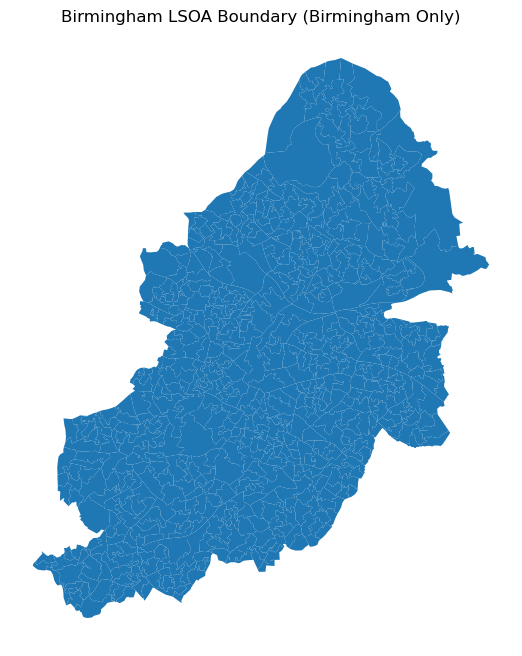

In [91]:
# I plot the Birmingham boundary to confirm I am not visualizing West Midlands.
ax = bham_lsoa.plot(figsize=(8, 8))
plt.title("Birmingham LSOA Boundary (Birmingham Only)")
plt.axis("off")
plt.show()


### Loading Crime data for bIrminghsm

In [92]:
# I load the OSM POI file.
PATH_POI = "/Users/dell/Downloads/west-midlands-260208-free/gis_osm_pois_free_1.shp"
gdf_poi = gpd.read_file(PATH_POI).to_crs("EPSG:4326")

gdf_poi.head()



,osm_id,code,fclass,name,geometry
0,212781,2907,camera_surveillance,None,POINT (-1.91219 52.53054)
1,645729,2004,post_box,None,POINT (-1.81694 52.55039)
2,645731,2004,post_box,None,POINT (-1.82333 52.55445)
3,645734,2004,post_box,None,POINT (-1.82826 52.5544)
4,645738,2006,telephone,None,POINT (-1.82813 52.5543)


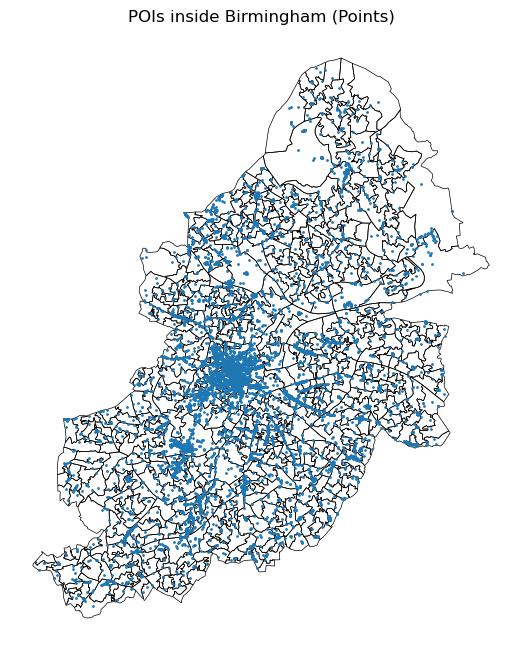

POIs inside Birmingham: 9396


In [93]:
# I clip POIs to Birmingham using spatial join (inner).
gdf_poi_bham = gpd.sjoin(gdf_poi, bham_lsoa, how="inner", predicate="intersects").copy()

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
bham_lsoa.plot(ax=ax, color="none", edgecolor="black", linewidth=0.5)
gdf_poi_bham.plot(ax=ax, markersize=1)
plt.title("POIs inside Birmingham (Points)")
plt.axis("off")
plt.show()

print("POIs inside Birmingham:", len(gdf_poi_bham))


In [94]:
# I compute POI counts and number of POI types per Birmingham LSOA.
df_poi_counts = gdf_poi_bham.groupby("lsoa21cd").size().reset_index(name="poi_counts")
df_poi_types  = gdf_poi_bham.groupby("lsoa21cd")["fclass"].nunique().reset_index(name="poi_types")

bham_lsoa_poi = bham_lsoa.merge(df_poi_counts, on="lsoa21cd", how="left")
bham_lsoa_poi = bham_lsoa_poi.merge(df_poi_types,  on="lsoa21cd", how="left")
bham_lsoa_poi[["poi_counts", "poi_types"]] = bham_lsoa_poi[["poi_counts", "poi_types"]].fillna(0)

bham_lsoa_poi.head()


,geo_point_2d,local_authority_code,local_authority_name,lsoa21cd,lsoa21nm,bng_e,bng_n,lat,long,geometry,poi_counts,poi_types
0,"{ ""lon"": -1.8072527979226209, ""lat"": 52.460639...",E08000025,Birmingham,E01008885,Birmingham 076A,413207,284818,52.4612,-1.80704,"POLYGON ((-1.80395 52.46102, -1.80415 52.46083...",1.0,1.0
1,"{ ""lon"": -1.8043212122725283, ""lat"": 52.457523...",E08000025,Birmingham,E01008888,Birmingham 076C,413431,284485,52.4582,-1.80376,"POLYGON ((-1.80319 52.46056, -1.79795 52.45783...",4.0,3.0
2,"{ ""lon"": -1.8335903759491261, ""lat"": 52.454662...",E08000025,Birmingham,E01008889,Birmingham 078D,411448,283926,52.4532,-1.83296,"POLYGON ((-1.83807 52.45946, -1.83916 52.45746...",10.0,5.0
3,"{ ""lon"": -1.8093219175362067, ""lat"": 52.452875...",E08000025,Birmingham,E01008891,Birmingham 089B,413145,283768,52.4517,-1.80800,"POLYGON ((-1.81186 52.45585, -1.81106 52.45526...",5.0,4.0
4,"{ ""lon"": -1.8191489954999134, ""lat"": 52.472336...",E08000025,Birmingham,E01008896,Birmingham 066B,412396,286061,52.4724,-1.81893,"POLYGON ((-1.81692 52.47312, -1.8164 52.4727, ...",0.0,0.0


In [95]:

bham_lsoa_poi_proj = bham_lsoa_poi.to_crs("EPSG:27700")

# Computing centroids in projected CRS
bham_lsoa_poi_proj["centroid_x"] = bham_lsoa_poi_proj.geometry.centroid.x
bham_lsoa_poi_proj["centroid_y"] = bham_lsoa_poi_proj.geometry.centroid.y

# Converting back to WGS84
bham_lsoa_poi = bham_lsoa_poi_proj.to_crs("EPSG:4326")


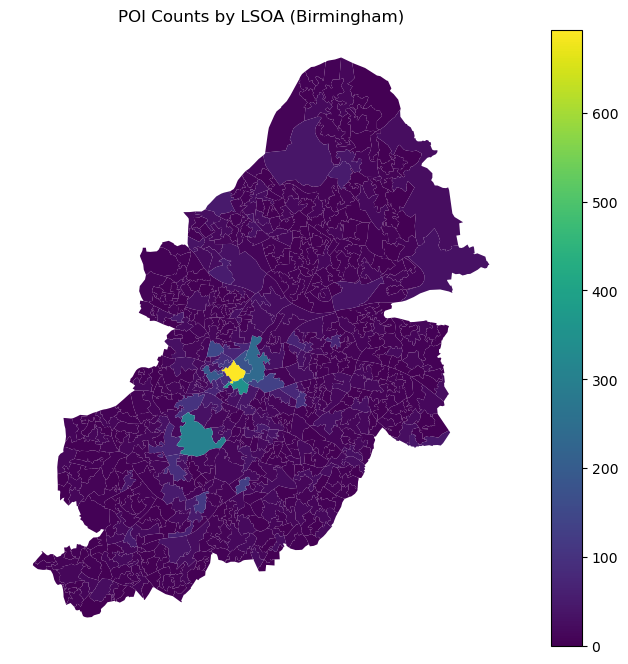

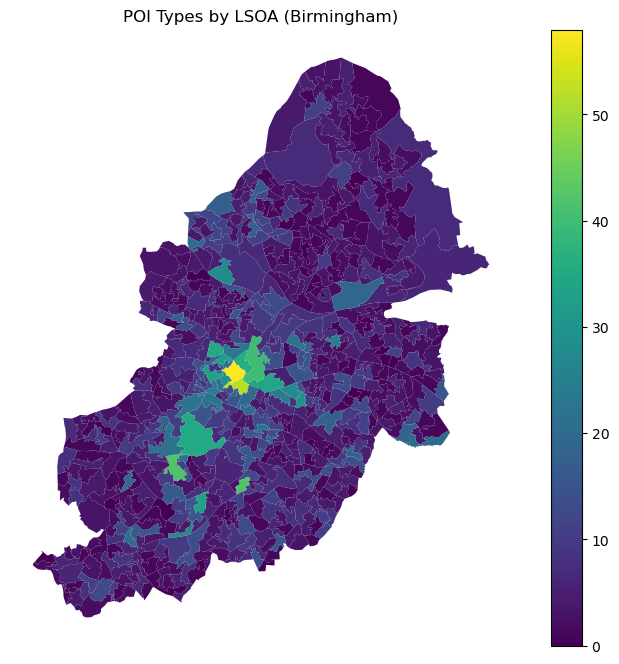

In [96]:
# I map POI counts to check if POIs are distributed reasonably across Birmingham.
ax = bham_lsoa_poi.plot(column="poi_counts", legend=True, figsize=(10, 8))
plt.title("POI Counts by LSOA (Birmingham)")
plt.axis("off")
plt.show()

# I map POI types to check diversity of POIs per LSOA.
ax = bham_lsoa_poi.plot(column="poi_types", legend=True, figsize=(10, 8))
plt.title("POI Types by LSOA (Birmingham)")
plt.axis("off")
plt.show()


### LOad Crimes + Crime Points Map

In [97]:
# I load the Birmingham crime data and keep only columns I need.
PATH_CRIME = "birmingham_crime_2023_2025.csv"
df_crime = pd.read_csv(PATH_CRIME)

df = pd.read_csv(PATH_CRIME)


In [98]:

df.head()

,Crime ID,Month,Reported by,Falls within,Longitude,Latitude,Location,LSOA code,LSOA name,Crime type,Last outcome category,Context
0,NaN,2024-09,West Midlands Police,West Midlands Police,-1.850772,52.588709,On or near Seymour Gardens,E01009417,Birmingham 001A,Anti-social behaviour,NaN,NaN
1,7a8b7c7f0b8e6f113788e25ec5edf45268fd614ae70307...,2024-09,West Midlands Police,West Midlands Police,-1.849177,52.593202,On or near Russell Bank Road,E01009417,Birmingham 001A,Vehicle crime,Unable to prosecute suspect,NaN
2,620cd472328f788c78bb36d59e58a65fe3df5631692be7...,2024-09,West Midlands Police,West Midlands Police,-1.849790,52.590937,On or near Walsall Road,E01009417,Birmingham 001A,Vehicle crime,Investigation complete; no suspect identified,NaN
3,242dabdcb663b6fc50b7a7cdb5a32c12c6b409fe7d8f1e...,2024-09,West Midlands Police,West Midlands Police,-1.847123,52.593864,On or near Bramble Way,E01009417,Birmingham 001A,Violence and sexual offences,Action to be taken by another organisation,NaN
4,482aa09a8759507ae8fc3ce5e2ae954bec63e0b7695f42...,2024-09,West Midlands Police,West Midlands Police,-1.849790,52.590937,On or near Walsall Road,E01009417,Birmingham 001A,Violence and sexual offences,Investigation complete; no suspect identified,NaN


In [99]:
crime_type_counts = df["Crime type"].value_counts()
crime_type_counts


Crime type
Violence and sexual offences    413537
Vehicle crime                    93904
Shoplifting                      86578
Criminal damage and arson        77786
Anti-social behaviour            75023
Other theft                      65781
Public order                     62414
Burglary                         51842
Drugs                            24853
Robbery                          22706
Possession of weapons            19781
Other crime                      19420
Theft from the person             9401
Bicycle theft                     6035
Name: count, dtype: int64

<Axes: title={'center': 'Crime Type Distribution in Birmingham (2023–2025)'}, xlabel='Crime type'>

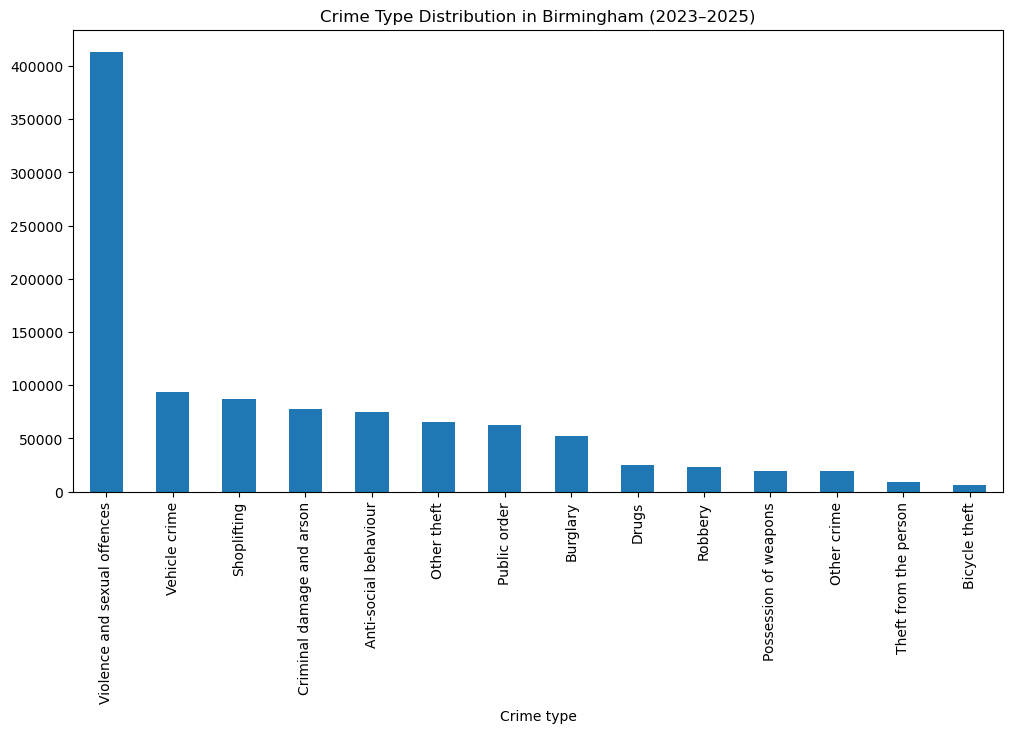

In [100]:
crime_type_counts.plot(kind="bar", figsize=(12,6), title="Crime Type Distribution in Birmingham (2023–2025)")


In [101]:
df_crime["Month"] = pd.to_datetime(df_crime["Month"])

df_crime = df_crime[["Month", "Longitude", "Latitude", "LSOA code", "LSOA name", "Crime type"]].copy()
df_crime.head()

,Month,Longitude,Latitude,LSOA code,LSOA name,Crime type
0,2024-09-01,-1.850772,52.588709,E01009417,Birmingham 001A,Anti-social behaviour
1,2024-09-01,-1.849177,52.593202,E01009417,Birmingham 001A,Vehicle crime
2,2024-09-01,-1.849790,52.590937,E01009417,Birmingham 001A,Vehicle crime
3,2024-09-01,-1.847123,52.593864,E01009417,Birmingham 001A,Violence and sexual offences
4,2024-09-01,-1.849790,52.590937,E01009417,Birmingham 001A,Violence and sexual offences


### Loading POI Data + Assigning to LSOA

In [102]:

# I load the Birmingham crime data and keep only columns I need.
PATH_CRIME = "birm_lsoa_2023_2025.csv"
df_crime = pd.read_csv(PATH_CRIME)

df_crime["Month"] = pd.to_datetime(df_crime["Month"])

df_crime = df_crime[["Month", "Longitude", "Latitude", "LSOA code", "LSOA name", "Crime type"]].copy()
df_crime.head()



,Month,Longitude,Latitude,LSOA code,LSOA name,Crime type
0,2024-09-01,-1.850772,52.588709,E01009417,Birmingham 001A,Anti-social behaviour
1,2024-09-01,-1.849177,52.593202,E01009417,Birmingham 001A,Vehicle crime
2,2024-09-01,-1.849790,52.590937,E01009417,Birmingham 001A,Vehicle crime
3,2024-09-01,-1.847123,52.593864,E01009417,Birmingham 001A,Violence and sexual offences
4,2024-09-01,-1.849790,52.590937,E01009417,Birmingham 001A,Violence and sexual offences


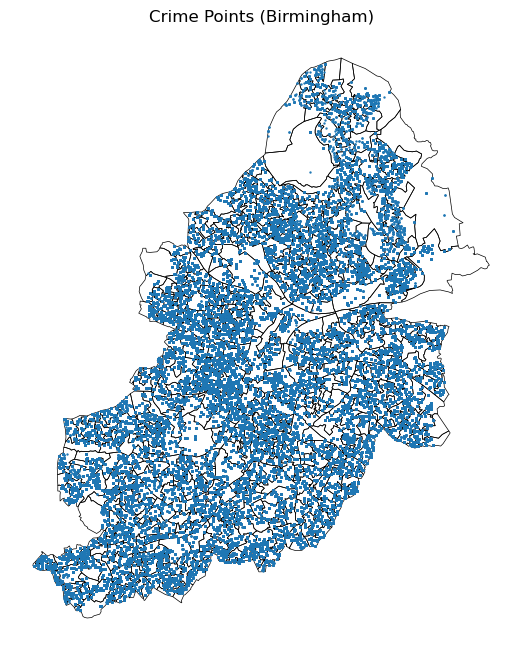

In [103]:
# I convert crimes to a GeoDataFrame (points).
gdf_crime = gpd.GeoDataFrame(
    df_crime,
    geometry=gpd.points_from_xy(df_crime["Longitude"], df_crime["Latitude"]),
    crs="EPSG:4326"
)

# I plot crime points over Birmingham boundary to confirm spatial scope.
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
bham_lsoa.plot(ax=ax, color="none", edgecolor="black", linewidth=0.5)
gdf_crime.plot(ax=ax, markersize=0.5)
plt.title("Crime Points (Birmingham)")
plt.axis("off")
plt.show()


### Spatial Join:Crime -LSOA + Add POI + Violent Flag

In [104]:
# I attach each crime point to a Birmingham LSOA polygon.
gdf_crime_lsoa = gpd.sjoin(gdf_crime, bham_lsoa_poi, how="inner", predicate="intersects").copy()

print("Crimes in Birmingham polygons:", len(gdf_crime_lsoa))
gdf_crime_lsoa.head()


Crimes in Birmingham polygons: 458242


,Month,Longitude,Latitude,LSOA code,LSOA name,Crime type,geometry,index_right,geo_point_2d,local_authority_code,local_authority_name,lsoa21cd,lsoa21nm,bng_e,bng_n,lat,long,poi_counts,poi_types,centroid_x,centroid_y
0,2024-09-01,-1.850772,52.588709,E01009417,Birmingham 001A,Anti-social behaviour,POINT (-1.85077 52.58871),156,"{ ""lon"": -1.8497043602559771, ""lat"": 52.592358...",E08000025,Birmingham,E01009417,Birmingham 001A,410270,299342,52.5918,-1.84982,2.0,1.0,410278.507233,299406.091464
1,2024-09-01,-1.849177,52.593202,E01009417,Birmingham 001A,Vehicle crime,POINT (-1.84918 52.5932),156,"{ ""lon"": -1.8497043602559771, ""lat"": 52.592358...",E08000025,Birmingham,E01009417,Birmingham 001A,410270,299342,52.5918,-1.84982,2.0,1.0,410278.507233,299406.091464
2,2024-09-01,-1.849790,52.590937,E01009417,Birmingham 001A,Vehicle crime,POINT (-1.84979 52.59094),156,"{ ""lon"": -1.8497043602559771, ""lat"": 52.592358...",E08000025,Birmingham,E01009417,Birmingham 001A,410270,299342,52.5918,-1.84982,2.0,1.0,410278.507233,299406.091464
3,2024-09-01,-1.847123,52.593864,E01009417,Birmingham 001A,Violence and sexual offences,POINT (-1.84712 52.59386),156,"{ ""lon"": -1.8497043602559771, ""lat"": 52.592358...",E08000025,Birmingham,E01009417,Birmingham 001A,410270,299342,52.5918,-1.84982,2.0,1.0,410278.507233,299406.091464
4,2024-09-01,-1.849790,52.590937,E01009417,Birmingham 001A,Violence and sexual offences,POINT (-1.84979 52.59094),156,"{ ""lon"": -1.8497043602559771, ""lat"": 52.592358...",E08000025,Birmingham,E01009417,Birmingham 001A,410270,299342,52.5918,-1.84982,2.0,1.0,410278.507233,299406.091464


In [105]:
# I label violent crimes exactly as "Violence and sexual offences".
gdf_crime_lsoa["is_violent"] = gdf_crime_lsoa["Crime type"].eq("Violence and sexual offences")

gdf_crime_lsoa[["Crime type", "is_violent"]].head()


,Crime type,is_violent
0,Anti-social behaviour,False
1,Vehicle crime,False
2,Vehicle crime,False
3,Violence and sexual offences,True
4,Violence and sexual offences,True


### Audit : Crime Type Frequency

In [106]:
# I audit the crime type distribution to prove the top category.
gdf_crime_lsoa["Crime type"].value_counts()


Crime type
Violence and sexual offences    187271
Vehicle crime                    39820
Shoplifting                      33507
Criminal damage and arson        33019
Anti-social behaviour            32548
Other theft                      30470
Public order                     28436
Burglary                         23428
Robbery                          12414
Drugs                            12109
Possession of weapons             9707
Other crime                       7710
Theft from the person             5301
Bicycle theft                     2502
Name: count, dtype: int64

### Aggregation : LSOA x Month (All/Violent/Non-Violent)

In [107]:
# I aggregate all crimes per LSOA per month.
df_all = (
    gdf_crime_lsoa
    .groupby(["lsoa21cd", "Month"])
    .size()
    .reset_index(name="crime_counts")
)

# I aggregate violent crimes.
df_violent = (
    gdf_crime_lsoa[gdf_crime_lsoa["is_violent"]]
    .groupby(["lsoa21cd", "Month"])
    .size()
    .reset_index(name="violent_counts")
)

# I aggregate non-violent crimes.
df_nonviolent = (
    gdf_crime_lsoa[~gdf_crime_lsoa["is_violent"]]
    .groupby(["lsoa21cd", "Month"])
    .size()
    .reset_index(name="nonviolent_counts")
)

df_all.head()


,lsoa21cd,Month,crime_counts
0,E01008881,2023-01-01,28
1,E01008881,2023-02-01,23
2,E01008881,2023-03-01,25
3,E01008881,2023-04-01,19
4,E01008881,2023-05-01,49


### Build Panel + Lag Features + Next-Month Targets

In [108]:
model_df = bham_lsoa_poi[[
    "lsoa21cd",
    "poi_counts",
    "poi_types",
    "centroid_x",
    "centroid_y"
]].copy()

panel = df_all.merge(model_df, on="lsoa21cd", how="left")


# I add violent and non-violent monthly counts.
panel = panel.merge(df_violent, on=["lsoa21cd", "Month"], how="left")
panel = panel.merge(df_nonviolent, on=["lsoa21cd", "Month"], how="left")

panel[["violent_counts", "nonviolent_counts"]] = panel[["violent_counts", "nonviolent_counts"]].fillna(0)

# I sort for lag creation.
panel = panel.sort_values(["lsoa21cd", "Month"]).reset_index(drop=True)

panel.head()


,lsoa21cd,Month,crime_counts,poi_counts,poi_types,centroid_x,centroid_y,violent_counts,nonviolent_counts
0,E01008881,2023-01-01,28,29.0,13.0,412714.900709,285504.094432,10.0,18.0
1,E01008881,2023-02-01,23,29.0,13.0,412714.900709,285504.094432,8.0,15.0
2,E01008881,2023-03-01,25,29.0,13.0,412714.900709,285504.094432,11.0,14.0
3,E01008881,2023-04-01,19,29.0,13.0,412714.900709,285504.094432,8.0,11.0
4,E01008881,2023-05-01,49,29.0,13.0,412714.900709,285504.094432,19.0,30.0


In [109]:
panel = panel.merge(
    bham_lsoa_poi[["lsoa21cd", "centroid_x", "centroid_y"]],
    on="lsoa21cd",
    how="left"
)


In [110]:
# I create 1–3 month lags for total, violent, and non-violent.
for col in ["crime_counts", "violent_counts", "nonviolent_counts"]:
    panel[f"lag1_{col}"] = panel.groupby("lsoa21cd")[col].shift(1)
    panel[f"lag2_{col}"] = panel.groupby("lsoa21cd")[col].shift(2)
    panel[f"lag3_{col}"] = panel.groupby("lsoa21cd")[col].shift(3)

# I create next-month targets.
panel["y_next_all"]        = panel.groupby("lsoa21cd")["crime_counts"].shift(-1)
panel["y_next_violent"]    = panel.groupby("lsoa21cd")["violent_counts"].shift(-1)
panel["y_next_nonviolent"] = panel.groupby("lsoa21cd")["nonviolent_counts"].shift(-1)

# I drop rows with missing lags or missing target.
panel = panel.dropna().reset_index(drop=True)

panel.head()


,lsoa21cd,Month,crime_counts,poi_counts,poi_types,centroid_x_x,centroid_y_x,violent_counts,nonviolent_counts,centroid_x_y,centroid_y_y,lag1_crime_counts,lag2_crime_counts,lag3_crime_counts,lag1_violent_counts,lag2_violent_counts,lag3_violent_counts,lag1_nonviolent_counts,lag2_nonviolent_counts,lag3_nonviolent_counts,y_next_all,y_next_violent,y_next_nonviolent
0,E01008881,2023-04-01,19,29.0,13.0,412714.900709,285504.094432,8.0,11.0,412714.900709,285504.094432,25.0,23.0,28.0,11.0,8.0,10.0,14.0,15.0,18.0,49.0,19.0,30.0
1,E01008881,2023-05-01,49,29.0,13.0,412714.900709,285504.094432,19.0,30.0,412714.900709,285504.094432,19.0,25.0,23.0,8.0,11.0,8.0,11.0,14.0,15.0,23.0,7.0,16.0
2,E01008881,2023-06-01,23,29.0,13.0,412714.900709,285504.094432,7.0,16.0,412714.900709,285504.094432,49.0,19.0,25.0,19.0,8.0,11.0,30.0,11.0,14.0,32.0,12.0,20.0
3,E01008881,2023-07-01,32,29.0,13.0,412714.900709,285504.094432,12.0,20.0,412714.900709,285504.094432,23.0,49.0,19.0,7.0,19.0,8.0,16.0,30.0,11.0,23.0,8.0,15.0
4,E01008881,2023-08-01,23,29.0,13.0,412714.900709,285504.094432,8.0,15.0,412714.900709,285504.094432,32.0,23.0,49.0,12.0,7.0,19.0,20.0,16.0,30.0,34.0,12.0,22.0


In [111]:
#Reattaching centriod coordinates after dropping NA
panel = panel.merge(
    bham_lsoa_poi[["lsoa21cd", "centroid_x", "centroid_y"]],
    on="lsoa21cd",
    how="left"
)

### Birmingham-Only Choropleth (Latest Month)

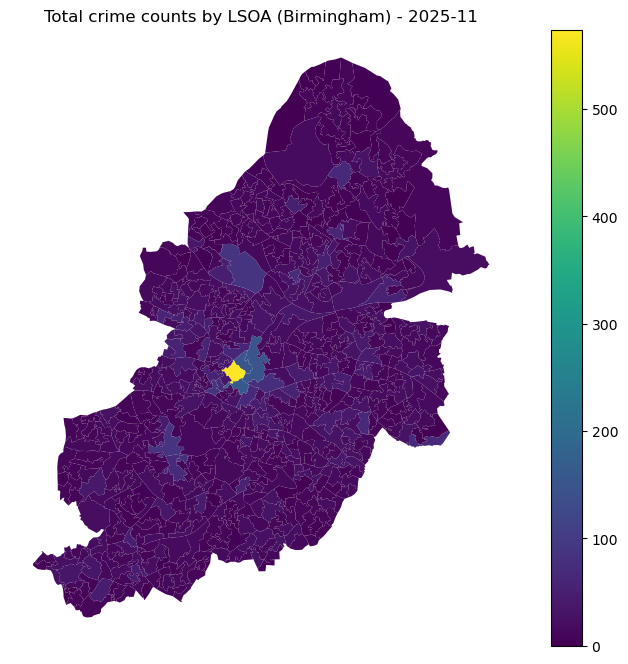

In [112]:
# Pickinng latest month
latest_month = panel["Month"].max()
panel_m = panel[panel["Month"] == latest_month].copy()

# Dropping columns that already exist in bham_lsoa_poi
panel_m = panel_m.drop(columns=[
    "poi_counts", "poi_types", "centroid_x", "centroid_y"
], errors="ignore")

# Merge safely
map_df = bham_lsoa_poi.merge(panel_m, on="lsoa21cd", how="left").fillna(0)

# Plot
ax = map_df.plot(column="crime_counts", legend=True, figsize=(10, 8))
plt.title(f"Total crime counts by LSOA (Birmingham) - {latest_month.strftime('%Y-%m')}")
plt.axis("off")
plt.show()


### Train/Test Split (Time-Aware)

In [113]:
# I split by time because I’m predicting next month counts.
months_sorted = sorted(panel["Month"].unique())
cut = int(len(months_sorted) * 0.8)

train_months = months_sorted[:cut]
test_months  = months_sorted[cut:]

gdf_train = panel[panel["Month"].isin(train_months)].copy()
gdf_test  = panel[panel["Month"].isin(test_months)].copy()

print("Train:", train_months[0], "→", train_months[-1], "| rows:", len(gdf_train))
print("Test :", test_months[0],  "→", test_months[-1],  "| rows:", len(gdf_test))


Train: 2023-04-01 00:00:00 → 2025-04-01 00:00:00 | rows: 16411
Test : 2025-05-01 00:00:00 → 2025-11-01 00:00:00 | rows: 4596


### Baseline Models + Metrics

In [114]:
# I define my modelling features (POI + lags).
feature_cols = [
    "poi_counts", "poi_types",
    "lag1_crime_counts", "lag2_crime_counts", "lag3_crime_counts",
    "lag1_violent_counts", "lag2_violent_counts", "lag3_violent_counts",
    "lag1_nonviolent_counts", "lag2_nonviolent_counts", "lag3_nonviolent_counts"
]

X_train = gdf_train[feature_cols]
X_test  = gdf_test[feature_cols]


### Random Forest Baseline : violent vs Non-Violent

In [115]:
# I train a fast Random Forest baseline for violent prediction.
y_train_v = gdf_train["y_next_violent"]
y_test_v  = gdf_test["y_next_violent"]

rf_v = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf_v.fit(X_train, y_train_v)
pred_v = rf_v.predict(X_test)

print("Violent RF Test:")
print("MSE:", mean_squared_error(y_test_v, pred_v))
print("MAE:", mean_absolute_error(y_test_v, pred_v))
print("R2 :", r2_score(y_test_v, pred_v))


Violent RF Test:
MSE: 16.34659245440917
MAE: 2.943221930963663
R2 : 0.7907918046805141


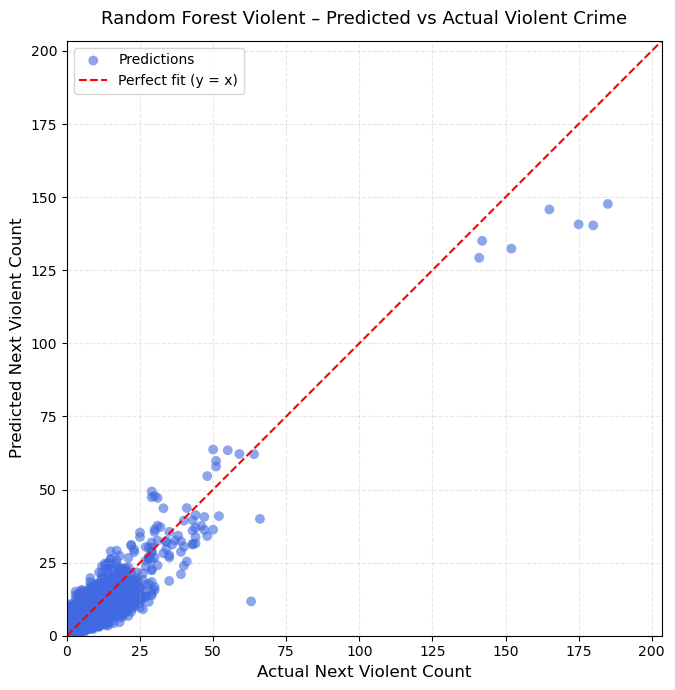

In [116]:

# I get the actual and predicted values (they should already exist from the previous cell)
actual = y_test_v.values if hasattr(y_test_v, 'values') else y_test_v
predicted = pred_v

# I make sure they are numpy arrays and flat
actual = np.asarray(actual).ravel()
predicted = np.asarray(predicted).ravel()

# I clip any silly negative predictions to zero since crime counts can't be negative
predicted = np.maximum(predicted, 0)

# I find a sensible max value for both axes with a little padding
max_val = max(actual.max(), predicted.max()) * 1.1
min_val = 0

# I create the figure
plt.figure(figsize=(7, 7))

# I plot the scatter points
plt.scatter(actual, predicted, 
            color='royalblue', alpha=0.6, s=50, 
            edgecolor='none', label='Predictions')

# I add the perfect prediction line (y = x) in red dashed
plt.plot([min_val, max_val], [min_val, max_val], 
         color='red', linestyle='--', linewidth=1.5, 
         label='Perfect fit (y = x)')

# I set equal limits so the diagonal looks 45 degrees
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

# I add labels and title
plt.xlabel('Actual Next Violent Count', fontsize=12)
plt.ylabel('Predicted Next Violent Count', fontsize=12)
plt.title('Random Forest Violent – Predicted vs Actual Violent Crime', fontsize=13, pad=12)

# I add a grid and legend
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper left', fontsize=10)

# I make the aspect ratio equal so it's visually fair
plt.gca().set_aspect('equal')

# I show the plot
plt.tight_layout()
plt.show()

### Random Forwst - Non-Violenrt

In [117]:
# I train a fast Random Forest baseline for non-violent prediction.
y_train_nv = gdf_train["y_next_nonviolent"]
y_test_nv  = gdf_test["y_next_nonviolent"]

rf_nv = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf_nv.fit(X_train, y_train_nv)
pred_nv = rf_nv.predict(X_test)

print("Non-violent RF Test:")
print("MSE:", mean_squared_error(y_test_nv, pred_nv))
print("MAE:", mean_absolute_error(y_test_nv, pred_nv))
print("R2 :", r2_score(y_test_nv, pred_nv))


Non-violent RF Test:
MSE: 30.303389670504767
MAE: 3.626217532153564
R2 : 0.906904515087307


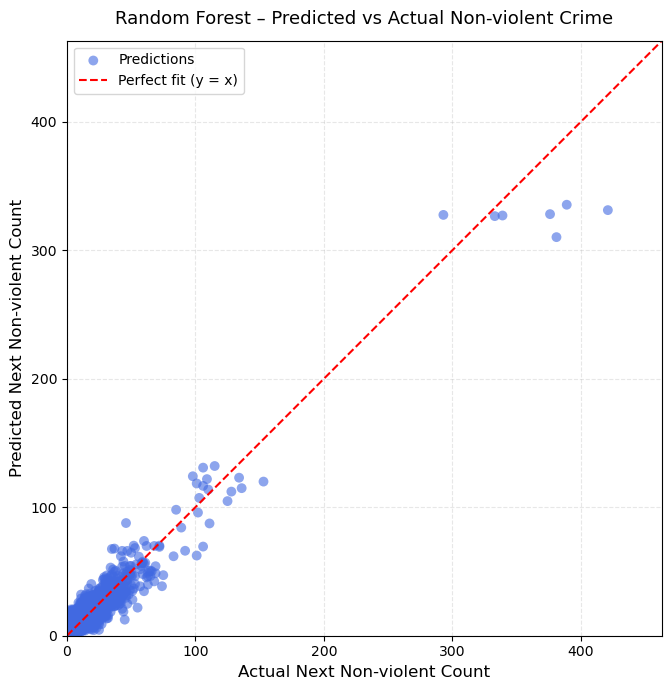

In [118]:


actual = y_test_nv.values if hasattr(y_test_nv, 'values') else y_test_nv
predicted = pred_nv
actual = np.asarray(actual).ravel()
predicted = np.asarray(predicted).ravel()
predicted = np.maximum(predicted, 0)           # clip negatives
max_val = max(actual.max(), predicted.max()) * 1.1
min_val = 0
plt.figure(figsize=(7, 7))
plt.scatter(actual, predicted, 
            color='royalblue', alpha=0.6, s=50, 
            edgecolor='none', label='Predictions')
plt.plot([min_val, max_val], [min_val, max_val], 
         color='red', linestyle='--', linewidth=1.5, 
         label='Perfect fit (y = x)')
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.xlabel('Actual Next Non-violent Count', fontsize=12)
plt.ylabel('Predicted Next Non-violent Count', fontsize=12)
plt.title('Random Forest – Predicted vs Actual Non-violent Crime', fontsize=13, pad=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper left', fontsize=10)
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.savefig("Random Forest.png")
plt.show()

### Random CV vs Spatial CV : Fold Maps

In [119]:
# I convert the geometry to a projected CRS so centroid coordinates are in meters.
gdf_train_proj = gpd.GeoDataFrame(
    gdf_train.merge(bham_lsoa_poi[["lsoa21cd", "geometry"]], on="lsoa21cd", how="left"),
    geometry="geometry",
    crs="EPSG:4326"
).to_crs(epsg=27700)

gdf_train_proj["centroid_x"] = gdf_train_proj.geometry.centroid.x
gdf_train_proj["centroid_y"] = gdf_train_proj.geometry.centroid.y

gdf_train_proj.head()


,lsoa21cd,Month,crime_counts,poi_counts,poi_types,centroid_x_x,centroid_y_x,violent_counts,nonviolent_counts,centroid_x_y,centroid_y_y,lag1_crime_counts,lag2_crime_counts,lag3_crime_counts,lag1_violent_counts,lag2_violent_counts,lag3_violent_counts,lag1_nonviolent_counts,lag2_nonviolent_counts,lag3_nonviolent_counts,y_next_all,y_next_violent,y_next_nonviolent,centroid_x,centroid_y,geometry
0,E01008881,2023-04-01,19,29.0,13.0,412714.900709,285504.094432,8.0,11.0,412714.900709,285504.094432,25.0,23.0,28.0,11.0,8.0,10.0,14.0,15.0,18.0,49.0,19.0,30.0,412714.901535,285504.094009,"POLYGON ((412974.953 285828.725, 413040.414 28..."
1,E01008881,2023-05-01,49,29.0,13.0,412714.900709,285504.094432,19.0,30.0,412714.900709,285504.094432,19.0,25.0,23.0,8.0,11.0,8.0,11.0,14.0,15.0,23.0,7.0,16.0,412714.901535,285504.094009,"POLYGON ((412974.953 285828.725, 413040.414 28..."
2,E01008881,2023-06-01,23,29.0,13.0,412714.900709,285504.094432,7.0,16.0,412714.900709,285504.094432,49.0,19.0,25.0,19.0,8.0,11.0,30.0,11.0,14.0,32.0,12.0,20.0,412714.901535,285504.094009,"POLYGON ((412974.953 285828.725, 413040.414 28..."
3,E01008881,2023-07-01,32,29.0,13.0,412714.900709,285504.094432,12.0,20.0,412714.900709,285504.094432,23.0,49.0,19.0,7.0,19.0,8.0,16.0,30.0,11.0,23.0,8.0,15.0,412714.901535,285504.094009,"POLYGON ((412974.953 285828.725, 413040.414 28..."
4,E01008881,2023-08-01,23,29.0,13.0,412714.900709,285504.094432,8.0,15.0,412714.900709,285504.094432,32.0,23.0,49.0,12.0,7.0,19.0,20.0,16.0,30.0,34.0,12.0,22.0,412714.901535,285504.094009,"POLYGON ((412974.953 285828.725, 413040.414 28..."


### Random CV Fold Maps

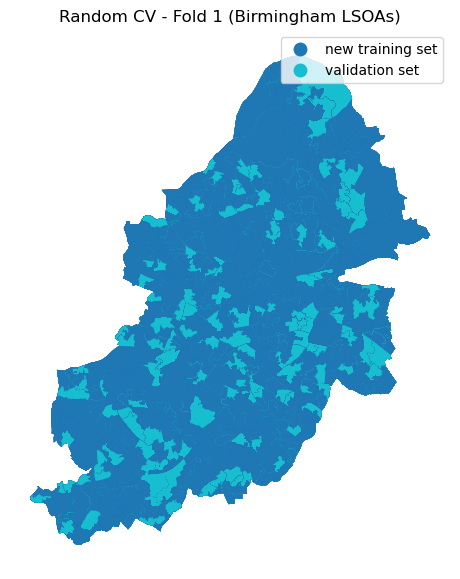

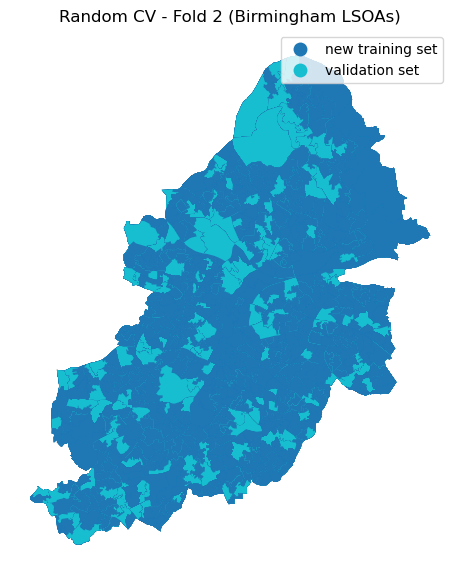

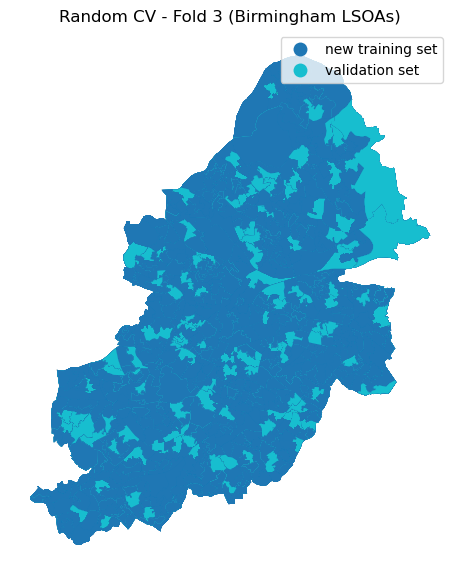

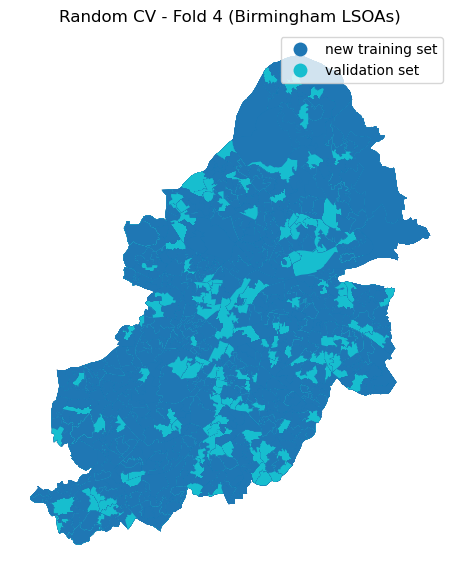

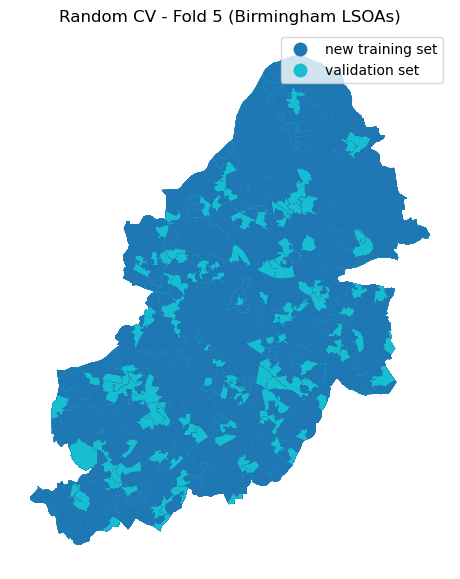

In [120]:
# I create random CV folds and plot where training vs validation sits spatially.
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for fold_id, (tr_idx, va_idx) in enumerate(kf.split(gdf_train_proj), start=1):
    fold_col = f"Random Fold {fold_id}"
    gdf_train_proj[fold_col] = "new training set"
    gdf_train_proj.loc[gdf_train_proj.index.isin(va_idx), fold_col] = "validation set"

    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    gdf_train_proj.plot(ax=ax, column=fold_col, legend=True)
    plt.title(f"Random CV - Fold {fold_id} (Birmingham LSOAs)")
    plt.axis("off")
    plt.show()


### Clustering-based Spatial CV + Cluster map

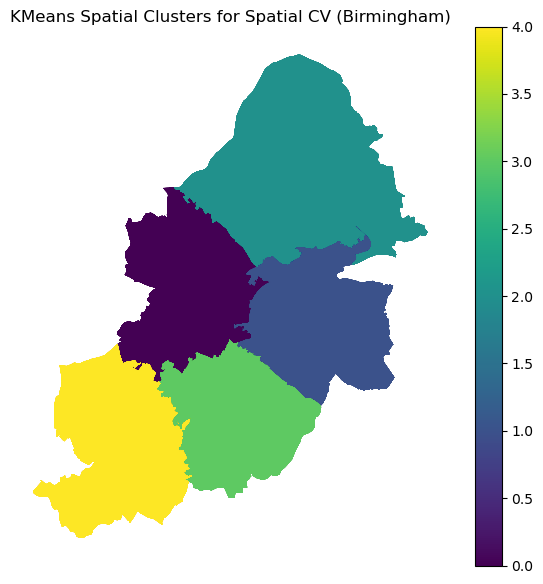

In [121]:
# I create 5 spatial clusters using LSOA centroid coordinates.
kmeans = KMeans(n_clusters=5, random_state=42)
gdf_train_proj["cluster"] = kmeans.fit_predict(gdf_train_proj[["centroid_x", "centroid_y"]])

fig, ax = plt.subplots(1, 1, figsize=(7, 7))
gdf_train_proj.plot(ax=ax, column="cluster", legend=True)
plt.title("KMeans Spatial Clusters for Spatial CV (Birmingham)")
plt.axis("off")
plt.show()


### Spatial CV Fold Maps using GroupKFold

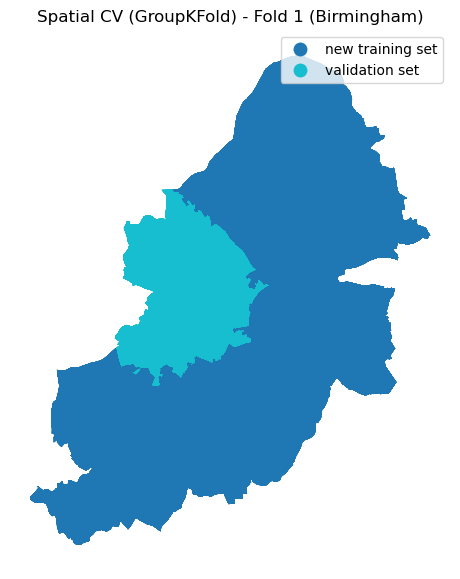

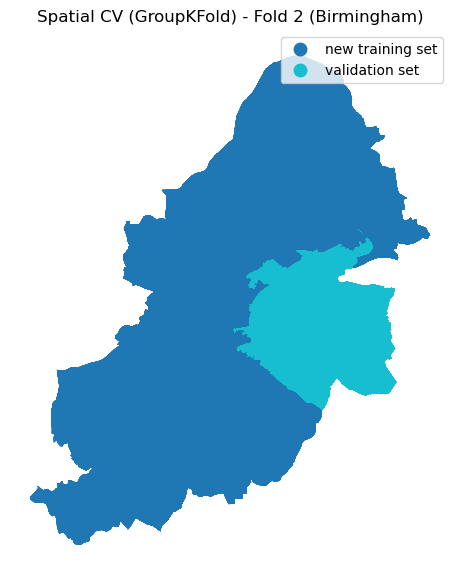

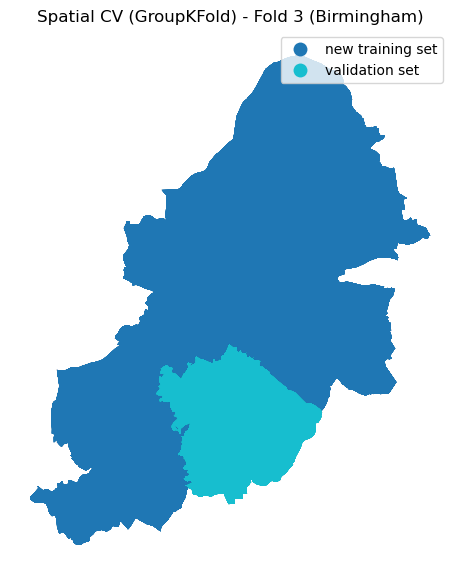

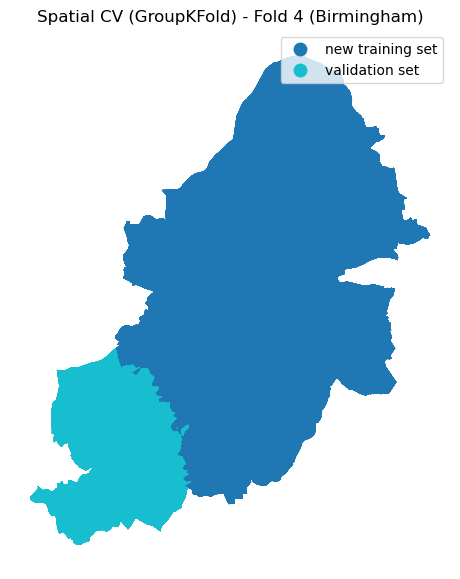

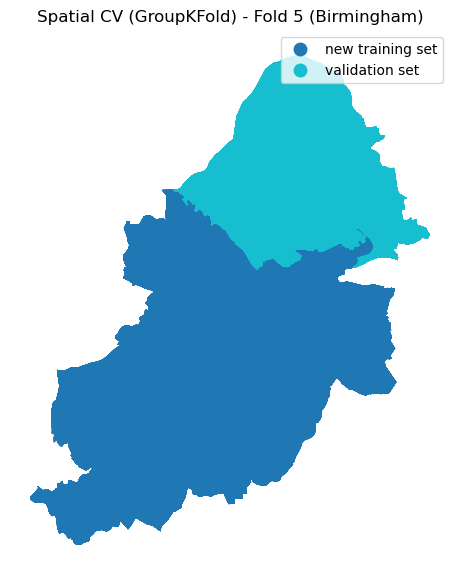

In [122]:
# I use GroupKFold so that each fold holds out an entire spatial cluster.
gkf = GroupKFold(n_splits=5)
groups = gdf_train_proj["cluster"].values

for fold_id, (tr_idx, va_idx) in enumerate(gkf.split(gdf_train_proj, groups=groups), start=1):
    fold_col = f"Spatial Fold {fold_id}"
    gdf_train_proj[fold_col] = "new training set"
    gdf_train_proj.loc[gdf_train_proj.index.isin(va_idx), fold_col] = "validation set"

    fig, ax = plt.subplots(1, 1, figsize=(7, 7))
    gdf_train_proj.plot(ax=ax, column=fold_col, legend=True)
    plt.title(f"Spatial CV (GroupKFold) - Fold {fold_id} (Birmingham)")
    plt.axis("off")
    plt.show()


### Support Vector Regression (SVR)

In [123]:
# I build an SVR pipeline with scaling and tune with Spatial CV.
svr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])

# I keep the search space small so it does not take forever.
param_dist = {
    "svr__kernel": ["rbf", "linear"],
    "svr__C": [0.1, 1, 10, 50, 100],
    "svr__gamma": ["scale", 0.1, 0.01],
    "svr__epsilon": [0.05, 0.1, 0.2]
}

X_tr = gdf_train_proj[feature_cols]
y_tr = gdf_train_proj["y_next_violent"]

search = RandomizedSearchCV(
    svr_pipe,
    param_distributions=param_dist,
    n_iter=20,
    scoring="neg_mean_squared_error",
    cv=gkf,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_tr, y_tr, groups=groups)

print("Best params:", search.best_params_)
print("Best CV MSE:", -search.best_score_)

best_svr_spatial = search.best_estimator_


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'svr__kernel': 'linear', 'svr__gamma': 'scale', 'svr__epsilon': 0.2, 'svr__C': 10}
Best CV MSE: 17.476836458366016


### SVR Violent Evaluating on time-based test set

In [124]:
# I evaluate the best spatial-CV tuned model on the held-out time test set.
# I need test geometry only for mapping later, but for prediction I just use feature matrix.
X_te = gdf_test[feature_cols]
y_te = gdf_test["y_next_violent"]

pred_v = best_svr_spatial.predict(X_te)

print("Violent SVR (Spatial CV tuned) Test:")
print("MSE:", mean_squared_error(y_te, pred_v))
print("MAE:", mean_absolute_error(y_te, pred_v))
print("R2 :", r2_score(y_te, pred_v))


Violent SVR (Spatial CV tuned) Test:
MSE: 16.494002562073867
MAE: 2.878807148275281
R2 : 0.7889052094966925


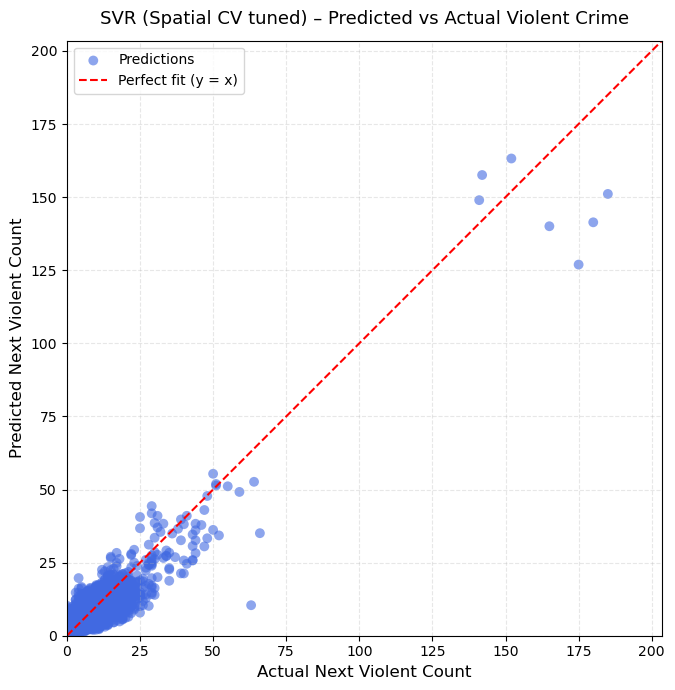

In [125]:


actual = y_te.values if hasattr(y_te, 'values') else y_te
predicted = pred_te
actual = np.asarray(actual).ravel()
predicted = np.asarray(predicted).ravel()
predicted = np.maximum(predicted, 0)           # clip negatives
max_val = max(actual.max(), predicted.max()) * 1.1
min_val = 0
plt.figure(figsize=(7, 7))
plt.scatter(actual, predicted, 
            color='royalblue', alpha=0.6, s=50, 
            edgecolor='none', label='Predictions')
plt.plot([min_val, max_val], [min_val, max_val], 
         color='red', linestyle='--', linewidth=1.5, 
         label='Perfect fit (y = x)')
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.xlabel('Actual Next Violent Count', fontsize=12)
plt.ylabel('Predicted Next Violent Count', fontsize=12)
plt.title('SVR (Spatial CV tuned) – Predicted vs Actual Violent Crime', fontsize=13, pad=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper left', fontsize=10)
plt.gca().set_aspect('equal')

plt.tight_layout()
plt.show()

### Prediction Maps + Residual Maps

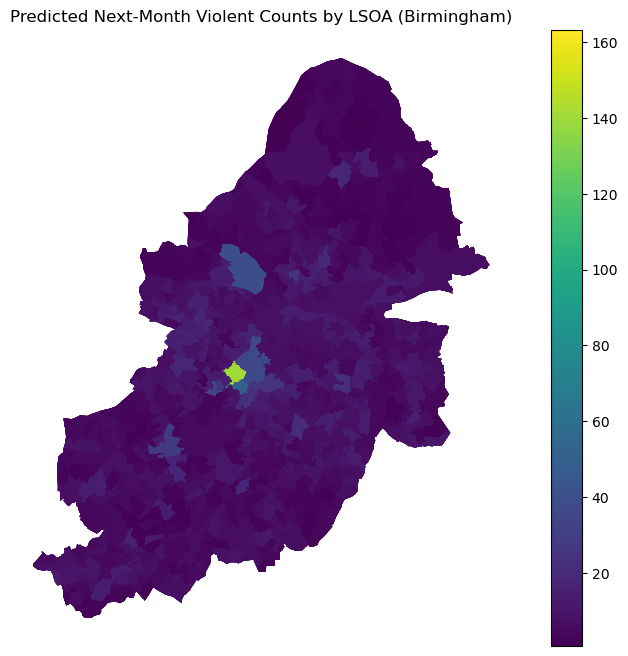

In [126]:
# I attach predictions back to a Birmingham LSOA geometry for mapping.
test_map = gdf_test.merge(bham_lsoa_poi[["lsoa21cd", "geometry"]], on="lsoa21cd", how="left")
test_map = gpd.GeoDataFrame(test_map, geometry="geometry", crs="EPSG:4326")

test_map["pred_next_violent"] = best_svr_spatial.predict(test_map[feature_cols])
test_map["resid_next_violent"] = test_map["y_next_violent"] - test_map["pred_next_violent"]

ax = test_map.plot(column="pred_next_violent", legend=True, figsize=(10, 8))
plt.title("Predicted Next-Month Violent Counts by LSOA (Birmingham)")
plt.axis("off")
plt.show()


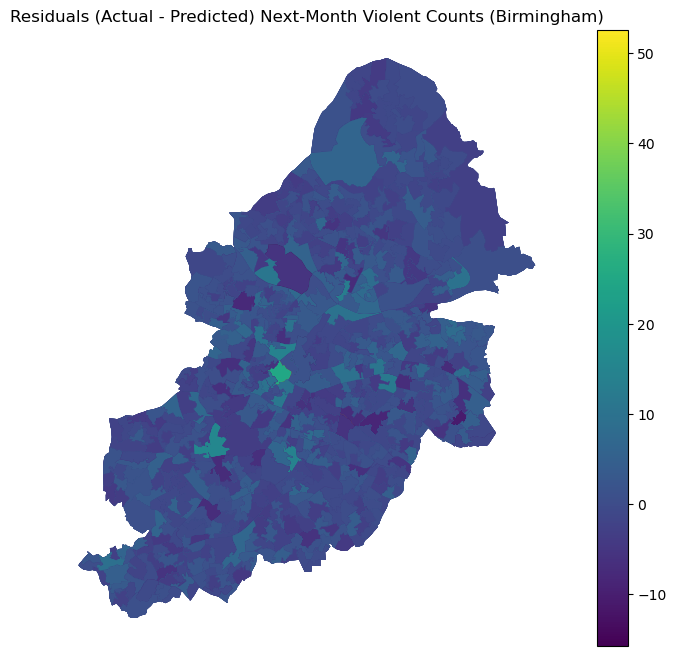

In [127]:
# I map residuals to see where my model under/over predicts spatially.
ax = test_map.plot(column="resid_next_violent", legend=True, figsize=(10, 8))
plt.title("Residuals (Actual - Predicted) Next-Month Violent Counts (Birmingham)")
plt.axis("off")
plt.show()


### SVR Non Violent Evaluating on time-based test set

In [131]:
# I evaluate the best spatial-CV tuned model on the held-out time test set.
# I need test geometry only for mapping later, but for prediction I just use feature matrix.
X_te = gdf_test[feature_cols]
y_nv = gdf_test["y_next_nonviolent"]

pred_nv = best_svr_spatial.predict(X_te)

print("Non Violent SVR (Spatial CV tuned) Test:")
print("MSE:", mean_squared_error(y_nv, pred_nv))
print("MAE:", mean_absolute_error(y_nv, pred_nv))
print("R2 :", r2_score(y_nv, pred_nv))


Non Violent SVR (Spatial CV tuned) Test:
MSE: 153.94573876110496
MAE: 5.1942360822959195
R2 : 0.5270610530360147


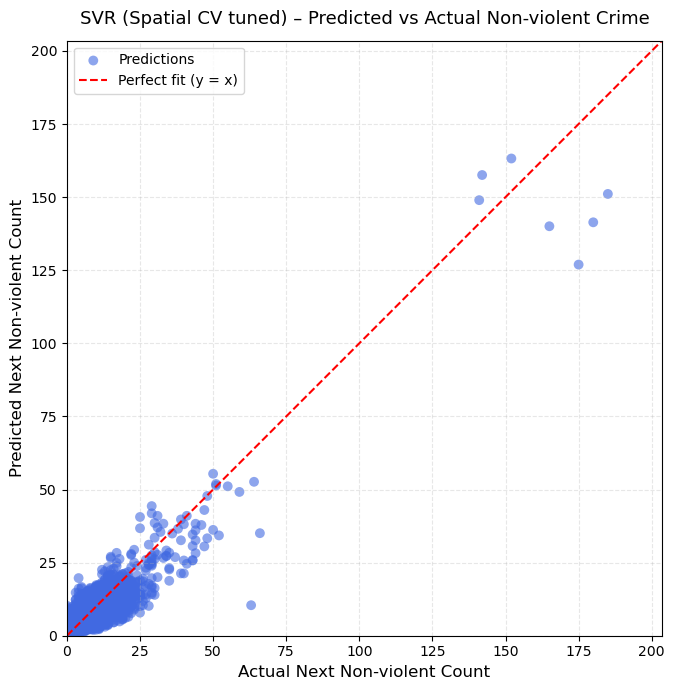

In [132]:

actual = y_te.values if hasattr(y_te, 'values') else y_te
predicted = pred_te
actual = np.asarray(actual).ravel()
predicted = np.asarray(predicted).ravel()
predicted = np.maximum(predicted, 0)           
max_val = max(actual.max(), predicted.max()) * 1.1
min_val = 0
plt.figure(figsize=(7, 7))
plt.scatter(actual, predicted, 
            color='royalblue', alpha=0.6, s=50, 
            edgecolor='none', label='Predictions')
plt.plot([min_val, max_val], [min_val, max_val], 
         color='red', linestyle='--', linewidth=1.5, 
         label='Perfect fit (y = x)')
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.xlabel('Actual Next Non-violent Count', fontsize=12)
plt.ylabel('Predicted Next Non-violent Count', fontsize=12)
plt.title('SVR (Spatial CV tuned) – Predicted vs Actual Non-violent Crime', fontsize=13, pad=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper left', fontsize=10)
plt.gca().set_aspect('equal')

plt.tight_layout()
plt.show()

## DEEP LEARNING MODELS

### LSTM

In [68]:


# I make sure my panel is sorted so sequences are correct.
panel = panel.copy()
panel = panel.sort_values(["lsoa21cd", "Month"])


# I choose how many months I want the LSTM to look back.
SEQ_LEN = 6  # I use 6 months history (you can change to 3, 6, 12)

# I define the features I feed into the LSTM at each month.
# I include counts + POI. POI is constant, but I repeat it each month in the sequence.
seq_feature_cols = ["violent_counts", "nonviolent_counts", "poi_counts", "poi_types"]

def make_sequences(df, target_col, seq_len=6):
    X_list, y_list = [], []

    # I loop through each LSOA so I don’t mix areas together.
    for lsoa, g in df.groupby("lsoa21cd"):
        g = g.sort_values("Month")

        # I extract the features and target as arrays.
        X_vals = g[seq_feature_cols].values.astype("float32")
        y_vals = g[target_col].values.astype("float32")

        # I slide a window of length seq_len, and predict the next step.
        for i in range(len(g) - seq_len):
            X_list.append(X_vals[i:i+seq_len])
            y_list.append(y_vals[i+seq_len])

    return np.array(X_list), np.array(y_list)

# I build datasets for violent and non-violent next-month prediction.
X_v, y_v = make_sequences(panel, target_col="violent_counts", seq_len=SEQ_LEN)
X_nv, y_nv = make_sequences(panel, target_col="nonviolent_counts", seq_len=SEQ_LEN)

print("Violent sequences X:", X_v.shape, "y:", y_v.shape)
print("Non-violent sequences X:", X_nv.shape, "y:", y_nv.shape)

Violent sequences X: (17053, 6, 4) y: (17053,)
Non-violent sequences X: (17053, 6, 4) y: (17053,)


In [69]:


# I do a simple split (fast baseline).
# For stricter time-split, we can split by Month later.
X_v_train, X_v_test, y_v_train, y_v_test = train_test_split(
    X_v, y_v, test_size=0.2, random_state=42
)

X_nv_train, X_nv_test, y_nv_train, y_nv_test = train_test_split(
    X_nv, y_nv, test_size=0.2, random_state=42
)

print("Violent train:", X_v_train.shape, "test:", X_v_test.shape)
print("Non-violent train:", X_nv_train.shape, "test:", X_nv_test.shape)

Violent train: (13642, 6, 4) test: (3411, 6, 4)
Non-violent train: (13642, 6, 4) test: (3411, 6, 4)


#### Violent

In [70]:


tf.random.set_seed(42)

# I build LSTM model (simple and fast).
model_v = models.Sequential([
    layers.Input(shape=(X_v_train.shape[1], X_v_train.shape[2])),
    layers.LSTM(64),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

model_v.compile(optimizer="adam", loss="mse", metrics=["mae"])

history_v = model_v.fit(
    X_v_train, y_v_train,
    validation_split=0.2,
    epochs=30,
    batch_size=64,
    verbose=1
)

# I evaluate on the test set.
loss_v, mae_v = model_v.evaluate(X_v_test, y_v_test, verbose=0)


# Generate predictions to calculate R2 and check MSE consistency
y_v_pred = model_v.predict(X_v_test)

mse_v = loss_v 
r2_v = r2_score(y_v_test, y_v_pred)

print("Violent LSTM Test MSE: ", mse_v)
print("Violent LSTM Test MAE: ", mae_v)
print("Violent LSTM Test R2:  ", r2_v)

Epoch 1/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 63.1742 - mae: 3.8760 - val_loss: 68.5147 - val_mae: 3.4292
Epoch 2/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.0730 - mae: 3.0162 - val_loss: 53.8327 - val_mae: 3.3072
Epoch 3/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 31.4364 - mae: 2.9014 - val_loss: 44.0961 - val_mae: 3.2167
Epoch 4/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 27.3787 - mae: 2.8600 - val_loss: 37.6667 - val_mae: 3.2329
Epoch 5/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 25.4096 - mae: 2.8525 - val_loss: 36.6008 - val_mae: 3.2122
Epoch 6/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 23.9811 - mae: 2.8363 - val_loss: 30.7558 - val_mae: 3.1574
Epoch 7/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 23.4990 - mae: 2.8469 - val_loss: 29.7708 - val_mae: 3.1004
Epoch 8/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 21.5112 - mae: 2.8145 - val_loss: 31.3533 - val_mae: 3.1476
Epoch 9/30
171/171 ━━━━━━━━━━━━━━━━━━━━

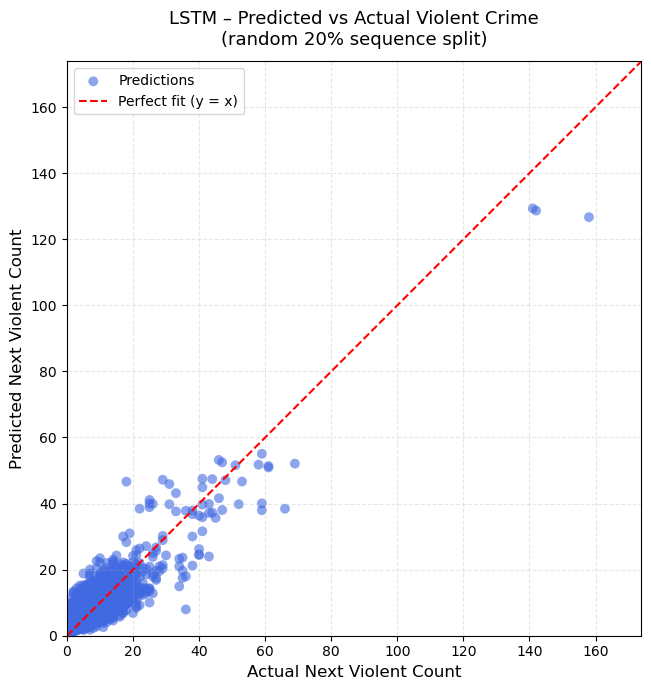

In [71]:
# I generate the predictions on the LSTM test set (this line was missing)
predicted = model_v.predict(X_v_test, verbose=0).ravel()
# I use the corresponding true values from the sequence split
actual = y_v_test
actual = np.asarray(actual).ravel()
predicted = np.asarray(predicted).ravel()
predicted = np.maximum(predicted, 0)           # clip negatives
max_val = max(actual.max(), predicted.max()) * 1.1
min_val = 0
plt.figure(figsize=(7, 7))
plt.scatter(actual, predicted, 
            color='royalblue', alpha=0.6, s=50, 
            edgecolor='none', label='Predictions')
plt.plot([min_val, max_val], [min_val, max_val], 
         color='red', linestyle='--', linewidth=1.5, 
         label='Perfect fit (y = x)')

plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.xlabel('Actual Next Violent Count', fontsize=12)
plt.ylabel('Predicted Next Violent Count', fontsize=12)
plt.title('LSTM – Predicted vs Actual Violent Crime\n(random 20% sequence split)', fontsize=13, pad=12)

plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper left', fontsize=10)
plt.gca().set_aspect('equal')

plt.tight_layout()
plt.show()

#### Non violent

In [72]:


tf.random.set_seed(42)

# LSTM model 
model_nv = models.Sequential([
    layers.Input(shape=(X_nv_train.shape[1], X_nv_train.shape[2])),
    layers.LSTM(64),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

model_nv.compile(optimizer="adam", loss="mse", metrics=["mae"])

history_nv = model_nv.fit(
    X_nv_train, y_nv_train,
    validation_split=0.2,
    epochs=30,
    batch_size=64,
    verbose=1
)

# I evaluate on the test set.
loss_nv, mae_nv = model_nv.evaluate(X_nv_test, y_nv_test, verbose=0)

y_nv_pred = model_nv.predict(X_nv_test)
mse_nv = loss_nv 
r2_nv = r2_score(y_nv_test, y_nv_pred)

print("Non-violent LSTM Test MSE: ", mse_nv)
print("Non-violent LSTM Test MAE: ", mae_nv)
print("Non-violent LSTM Test R2:  ", r2_nv)

Epoch 1/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 261.0495 - mae: 5.9595 - val_loss: 421.7452 - val_mae: 5.2306
Epoch 2/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 168.3261 - mae: 4.1677 - val_loss: 344.9476 - val_mae: 4.7832
Epoch 3/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 134.3797 - mae: 3.9056 - val_loss: 296.5072 - val_mae: 4.7712
Epoch 4/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 112.8560 - mae: 3.7919 - val_loss: 256.2279 - val_mae: 4.5699
Epoch 5/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 96.1334 - mae: 3.7027 - val_loss: 223.8246 - val_mae: 4.4031
Epoch 6/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 83.4304 - mae: 3.6320 - val_loss: 199.4514 - val_mae: 4.4093
Epoch 7/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 73.8283 - mae: 3.6053 - val_loss: 181.3384 - val_mae: 4.2828
Epoch 8/30
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 65.9543 - mae: 3.5712 - val_loss: 147.8841 - val_mae: 4.2174
Epoch 9/30
171/171 ━━━━━━━━

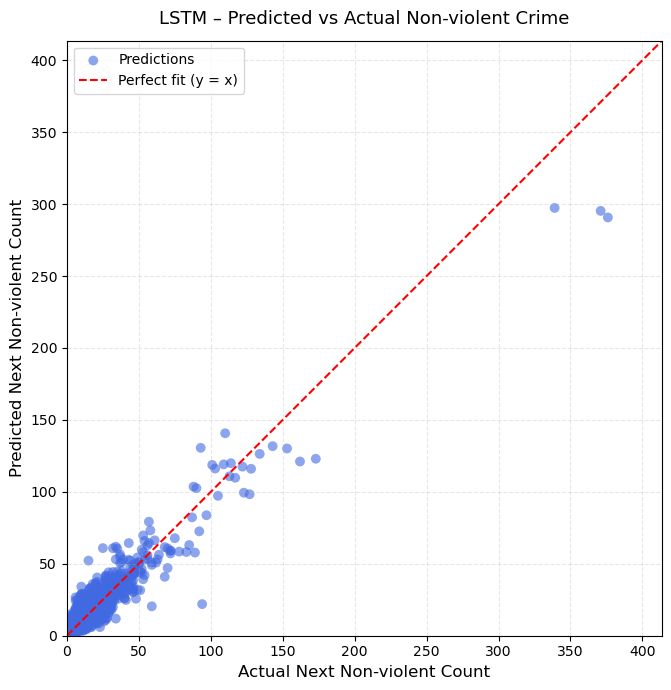

In [73]:
# I generate the predictions on the LSTM non-violent test set
predicted = model_nv.predict(X_nv_test, verbose=0).ravel()
# I use the corresponding true values from the sequence split
actual = y_nv_test
actual = np.asarray(actual).ravel()
predicted = np.asarray(predicted).ravel()
predicted = np.maximum(predicted, 0)           
max_val = max(actual.max(), predicted.max()) * 1.1
min_val = 0
plt.figure(figsize=(7, 7))

plt.scatter(actual, predicted, 
            color='royalblue', alpha=0.6, s=50, 
            edgecolor='none', label='Predictions')

plt.plot([min_val, max_val], [min_val, max_val], 
         color='red', linestyle='--', linewidth=1.5, 
         label='Perfect fit (y = x)')

plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.xlabel('Actual Next Non-violent Count', fontsize=12)
plt.ylabel('Predicted Next Non-violent Count', fontsize=12)
plt.title('LSTM – Predicted vs Actual Non-violent Crime', fontsize=13, pad=12)

plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(loc='upper left', fontsize=10)
plt.gca().set_aspect('equal')

plt.tight_layout()
plt.show()

#### Training Loss Plots

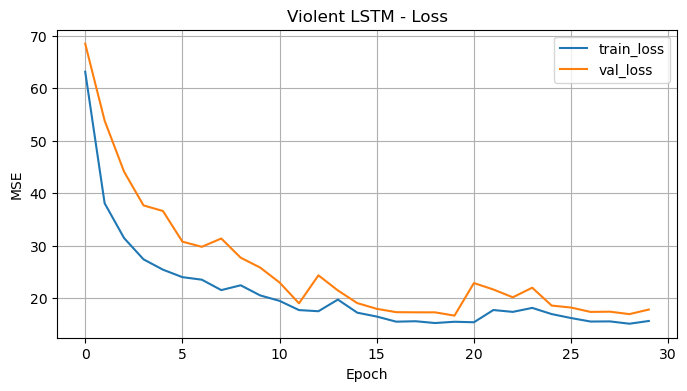

In [74]:


# I plot violent training curve
plt.figure(figsize=(8,4))
plt.plot(history_v.history["loss"], label="train_loss")
plt.plot(history_v.history["val_loss"], label="val_loss")
plt.title("Violent LSTM - Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)
plt.show()



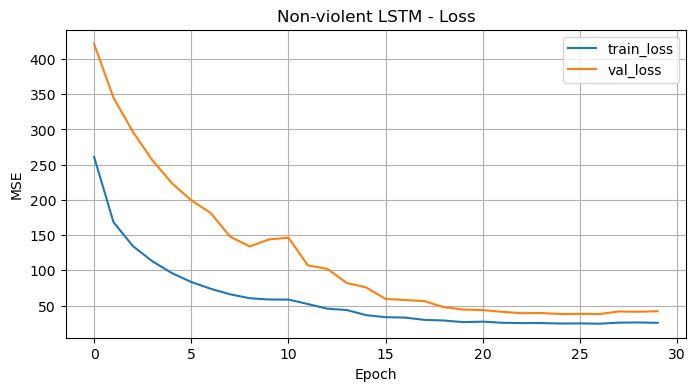

In [75]:
# I plot non-violent training curve
plt.figure(figsize=(8,4))
plt.plot(history_nv.history["loss"], label="train_loss")
plt.plot(history_nv.history["val_loss"], label="val_loss")
plt.title("Non-violent LSTM - Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)
plt.show()


#### NB : I used the same architecture for both Violent and Non-Violent to be fair

In [76]:
pred_test_lstm_violent = y_v_pred.ravel()
pred_test_lstm_nonviolent = y_nv_pred.ravel()

## My CNN Rebuild: Spatial + Temporal Crime Prediction

Here, I rebuild my CNN so that it uses both:
- temporal information through lag features
- spatial information through LSOA centroid coordinates

I evaluate the model in three ways:
1. Random CV
2. Spatial CV
3. Final held-out time test

### Preparing Features and Targets

In [50]:
# I extract my tabular features (POI + lag features).
X_train_tab = gdf_train[feature_cols].to_numpy().astype("float32")
X_test_tab  = gdf_test[feature_cols].to_numpy().astype("float32")



In [51]:
# I extract my spatial coordinates.
coords_train = gdf_train[["centroid_x", "centroid_y"]].to_numpy().astype("float32")
coords_test  = gdf_test[["centroid_x", "centroid_y"]].to_numpy().astype("float32")


In [52]:

# I scale tabular features.
x_scaler = StandardScaler()
X_train_tab_scaled = x_scaler.fit_transform(X_train_tab)
X_test_tab_scaled  = x_scaler.transform(X_test_tab)

# I scale coordinates separately.
coord_scaler = StandardScaler()
coords_train_scaled = coord_scaler.fit_transform(coords_train)
coords_test_scaled  = coord_scaler.transform(coords_test)



In [53]:
# I reshape tabular features into CNN format: (samples, steps, channels).
X_train_tab_cnn = X_train_tab_scaled.reshape(X_train_tab_scaled.shape[0], X_train_tab_scaled.shape[1], 1)
X_test_tab_cnn  = X_test_tab_scaled.reshape(X_test_tab_scaled.shape[0], X_test_tab_scaled.shape[1], 1)

# I prepare my targets.
y_train_violent    = gdf_train["y_next_violent"].to_numpy().astype("float32")
y_train_nonviolent = gdf_train["y_next_nonviolent"].to_numpy().astype("float32")

y_test_violent     = gdf_test["y_next_violent"].to_numpy().astype("float32")
y_test_nonviolent  = gdf_test["y_next_nonviolent"].to_numpy().astype("float32")


In [54]:

print("Tabular CNN input shape:", X_train_tab_cnn.shape)
print("Coordinate input shape :", coords_train_scaled.shape)
print("Violent target shape   :", y_train_violent.shape)
print("Non-violent target shape:", y_train_nonviolent.shape)

Tabular CNN input shape: (16411, 11, 1)
Coordinate input shape : (16411, 2)
Violent target shape   : (16411,)
Non-violent target shape: (16411,)


### Building CNN

In [55]:
# I build a hybrid model with two inputs:
# 1) a CNN branch for tabular lag/POI features
# 2) a dense branch for spatial coordinates
from tensorflow.keras.layers import Concatenate
from tensorflow.keras.models import Model



tab_input = Input(shape=(X_train_tab_cnn.shape[1], 1), name="tabular_input")
x = Conv1D(filters=32, kernel_size=3, activation="relu", padding="same")(tab_input)
x = Dropout(0.2)(x)
x = Conv1D(filters=32, kernel_size=3, activation="relu", padding="same")(x)
x = Flatten()(x)

coord_input = Input(shape=(2,), name="coord_input")
c = Dense(16, activation="relu")(coord_input)

merged = Concatenate()([x, c])
merged = Dense(64, activation="relu")(merged)
merged = Dropout(0.2)(merged)
output = Dense(1)(merged)

base_model = Model(inputs=[tab_input, coord_input], outputs=output)
base_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

base_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tabular_input       │ (None, 11, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 11, 32)    │        128 │ tabular_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 11, 32)    │          0 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 11, 32)    │      3,104 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ coord_input         │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 352)       │          0 │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 16)        │         48 │ coord_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 368)       │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │     23,616 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 26,961 (105.32 KB)

 Trainable params: 26,961 (105.32 KB)

 Non-trainable params: 0 (0.00 B)

### Rnadom CV Violent


Random CV - Violent - Fold 1
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 29.2744 - mae: 3.6421 - val_loss: 18.6240 - val_mae: 2.9712
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.2603 - mae: 3.0967 - val_loss: 16.7313 - val_mae: 2.8911
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.4017 - mae: 3.0687 - val_loss: 16.8887 - val_mae: 2.8869
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.2254 - mae: 3.0395 - val_loss: 16.5883 - val_mae: 2.8873
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.3572 - mae: 3.0585 - val_loss: 16.7743 - val_mae: 2.8724
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 17.7472 - mae: 3.0220 - val_loss: 16.5791 - val_mae: 2.8757
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.0082 - mae: 3.0313 - val_loss: 16.6854 - val_mae: 2.8677
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.6556 - mae: 3.0503 - val_loss: 17.1498 - val_mae: 2.8871
Epoch 9/5

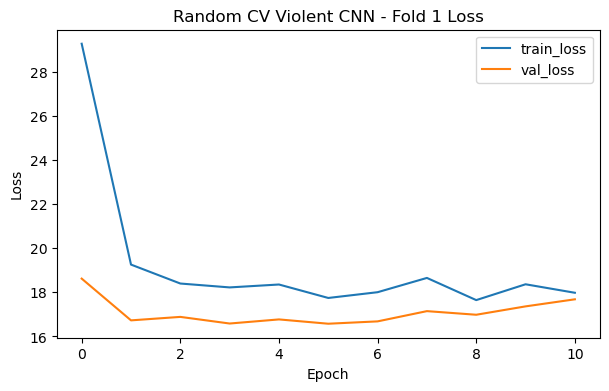


Random CV - Violent - Fold 2
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 28.5991 - mae: 3.6559 - val_loss: 19.0623 - val_mae: 2.9585
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.5973 - mae: 3.1035 - val_loss: 18.6558 - val_mae: 2.9467
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.0122 - mae: 3.0671 - val_loss: 19.1019 - val_mae: 2.9388
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.3395 - mae: 3.0381 - val_loss: 19.2466 - val_mae: 2.9454
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 17.9284 - mae: 3.0255 - val_loss: 17.6035 - val_mae: 2.9051
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.2692 - mae: 3.0473 - val_loss: 18.0043 - val_mae: 2.9125
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.5078 - mae: 3.0185 - val_loss: 18.6222 - val_mae: 2.9255
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.6926 - mae: 3.0450 - val_loss: 18.4450 - val_mae: 2.9178
Epoch 9/5

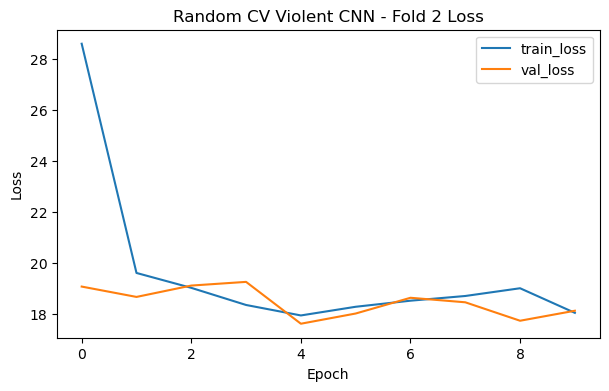


Random CV - Violent - Fold 3
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 29.9562 - mae: 3.6390 - val_loss: 16.7041 - val_mae: 2.9160
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.4799 - mae: 3.1162 - val_loss: 16.1970 - val_mae: 2.8768
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.5903 - mae: 3.0686 - val_loss: 16.0367 - val_mae: 2.8509
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.8851 - mae: 3.0953 - val_loss: 15.7761 - val_mae: 2.8519
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.4874 - mae: 3.0701 - val_loss: 15.8918 - val_mae: 2.8643
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.9344 - mae: 3.0451 - val_loss: 16.7347 - val_mae: 2.8689
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.0506 - mae: 3.0666 - val_loss: 15.6458 - val_mae: 2.8496
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.7643 - mae: 3.0540 - val_loss: 15.7185 - val_mae: 2.8483
Epoch 9/5

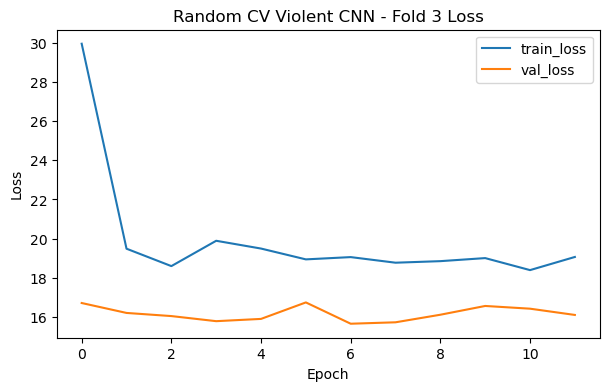


Random CV - Violent - Fold 4
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 25.2593 - mae: 3.5117 - val_loss: 17.7132 - val_mae: 3.0493
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.0259 - mae: 3.0678 - val_loss: 17.3886 - val_mae: 3.0418
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.5223 - mae: 3.0383 - val_loss: 21.7772 - val_mae: 3.1226
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.1288 - mae: 3.0421 - val_loss: 17.4190 - val_mae: 2.9816
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.5380 - mae: 3.0352 - val_loss: 16.9366 - val_mae: 2.9712
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.2847 - mae: 3.0199 - val_loss: 16.9422 - val_mae: 2.9567
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 17.2508 - mae: 2.9981 - val_loss: 17.1071 - val_mae: 2.9561
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.0278 - mae: 3.0274 - val_loss: 20.3003 - val_mae: 3.0571
Epoch 9/5

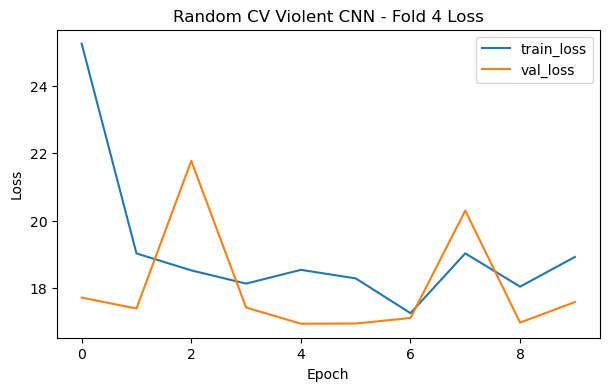


Random CV - Violent - Fold 5
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 25.7291 - mae: 3.5017 - val_loss: 17.7087 - val_mae: 3.0709
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.4896 - mae: 3.0590 - val_loss: 17.5521 - val_mae: 3.0374
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 20.2666 - mae: 3.0307 - val_loss: 17.9343 - val_mae: 3.0485
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.8722 - mae: 3.0105 - val_loss: 17.1837 - val_mae: 3.0368
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.9046 - mae: 3.0117 - val_loss: 18.6207 - val_mae: 3.0573
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.5950 - mae: 3.0041 - val_loss: 17.5891 - val_mae: 3.0490
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.9016 - mae: 3.0034 - val_loss: 17.5304 - val_mae: 3.0370
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.4247 - mae: 3.0481 - val_loss: 17.1637 - val_mae: 3.0273
Epoch 9/5

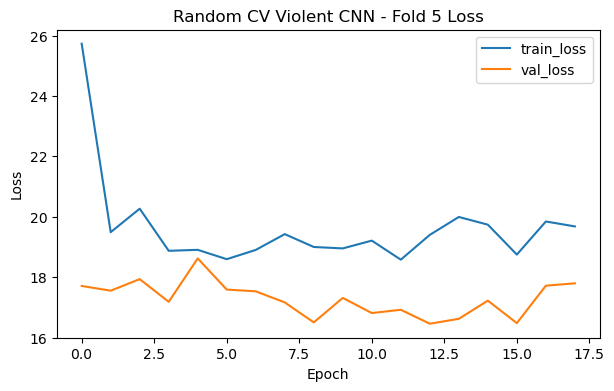


Random CV Violent Summary
   fold        mse       mae        r2
0     1  16.579084  2.875685  0.789314
1     2  17.603479  2.905134  0.759135
2     3  15.645808  2.849606  0.813297
3     4  16.936600  2.971172  0.748411
4     5  16.457941  3.025779  0.713861

Mean metrics
mse    16.644583
mae     2.925475
r2      0.764804
dtype: float64


In [56]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

random_results_violent = []

for fold_id, (tr_idx, va_idx) in enumerate(kf.split(X_train_tab_cnn), start=1):
    print("\n" + "="*60)
    print(f"Random CV - Violent - Fold {fold_id}")
    print("="*60)

    X_tr_tab = X_train_tab_cnn[tr_idx]
    X_va_tab = X_train_tab_cnn[va_idx]

    X_tr_coord = coords_train_scaled[tr_idx]
    X_va_coord = coords_train_scaled[va_idx]

    y_tr = y_train_violent[tr_idx]
    y_va = y_train_violent[va_idx]

    tab_input = Input(shape=(X_train_tab_cnn.shape[1], 1))
    x = Conv1D(32, 3, activation="relu", padding="same")(tab_input)
    x = Dropout(0.2)(x)
    x = Conv1D(32, 3, activation="relu", padding="same")(x)
    x = Flatten()(x)

    coord_input = Input(shape=(2,))
    c = Dense(16, activation="relu")(coord_input)

    merged = Concatenate()([x, c])
    merged = Dense(64, activation="relu")(merged)
    merged = Dropout(0.2)(merged)
    output = Dense(1)(merged)

    model = Model(inputs=[tab_input, coord_input], outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss="mse", metrics=["mae"])

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    history = model.fit(
        [X_tr_tab, X_tr_coord], y_tr,
        validation_data=([X_va_tab, X_va_coord], y_va),
        epochs=50,
        batch_size=64,
        verbose=1,
        callbacks=[es]
    )
    pred_va = model.predict([X_va_tab, X_va_coord], verbose=0).ravel()
    mse = mean_squared_error(y_va, pred_va)
    mae = mean_absolute_error(y_va, pred_va)
    r2  = r2_score(y_va, pred_va)

    random_results_violent.append({"fold": fold_id, "mse": mse, "mae": mae, "r2": r2})
    print(f"Fold {fold_id} -> MSE: {mse:.3f} | MAE: {mae:.3f} | R2: {r2:.3f}")

    plt.figure(figsize=(7,4))
    plt.plot(history.history["loss"], label="train_loss")
    plt.plot(history.history["val_loss"], label="val_loss")
    plt.title(f"Random CV Violent CNN - Fold {fold_id} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

random_results_violent_df = pd.DataFrame(random_results_violent)
print("\nRandom CV Violent Summary")
print(random_results_violent_df)
print("\nMean metrics")
print(random_results_violent_df[["mse", "mae", "r2"]].mean())

#### Random CV Non Violent


Random CV - Non-violent - Fold 1
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 73.5231 - mae: 4.8552 - val_loss: 40.8686 - val_mae: 3.9440
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 36.7800 - mae: 3.9524 - val_loss: 37.6306 - val_mae: 3.7201
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 39.7738 - mae: 3.8940 - val_loss: 53.3496 - val_mae: 3.8768
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 36.0060 - mae: 3.8134 - val_loss: 42.6205 - val_mae: 3.7336
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 35.2874 - mae: 3.8047 - val_loss: 39.0652 - val_mae: 3.6806
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 36.8013 - mae: 3.8013 - val_loss: 36.9524 - val_mae: 3.6485
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 35.0081 - mae: 3.8100 - val_loss: 37.6576 - val_mae: 3.6480
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 33.6848 - mae: 3.7753 - val_loss: 40.5903 - val_mae: 3.6880
Ep

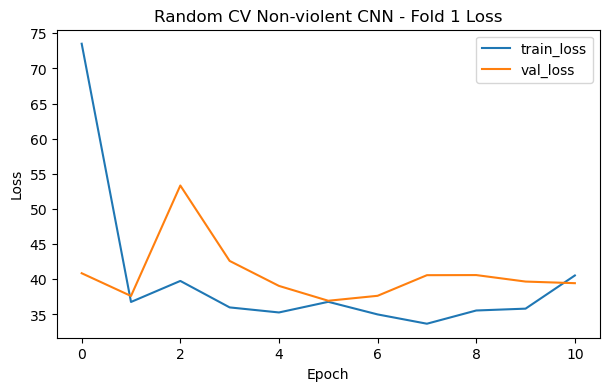


Random CV - Non-violent - Fold 2
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 70.9104 - mae: 4.8406 - val_loss: 36.0874 - val_mae: 3.8974
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 39.9708 - mae: 3.9073 - val_loss: 34.9008 - val_mae: 3.7501
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 36.1456 - mae: 3.8354 - val_loss: 38.9454 - val_mae: 3.7825
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 36.0289 - mae: 3.7711 - val_loss: 34.3149 - val_mae: 3.7192
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.1534 - mae: 3.7998 - val_loss: 40.5893 - val_mae: 3.8182
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 35.7709 - mae: 3.7785 - val_loss: 31.2367 - val_mae: 3.7035
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 34.0709 - mae: 3.7697 - val_loss: 39.3087 - val_mae: 3.8030
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 34.8260 - mae: 3.7393 - val_loss: 31.6359 - val_mae: 3.6852
Epo

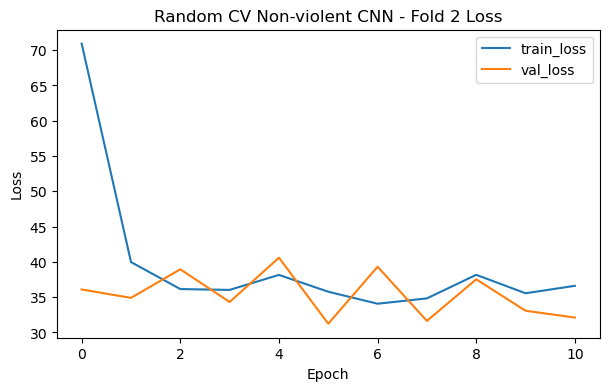


Random CV - Non-violent - Fold 3
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 80.1100 - mae: 4.9155 - val_loss: 33.2655 - val_mae: 3.7861
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 38.7266 - mae: 3.8942 - val_loss: 30.7949 - val_mae: 3.5960
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 37.4213 - mae: 3.8449 - val_loss: 30.5930 - val_mae: 3.5791
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 35.0091 - mae: 3.7919 - val_loss: 30.7456 - val_mae: 3.6378
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 37.8968 - mae: 3.8568 - val_loss: 30.8767 - val_mae: 3.5862
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 35.7109 - mae: 3.7792 - val_loss: 31.2395 - val_mae: 3.5540
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 35.7910 - mae: 3.7984 - val_loss: 30.9485 - val_mae: 3.6259
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 35.6581 - mae: 3.8209 - val_loss: 34.0030 - val_mae: 3.6770


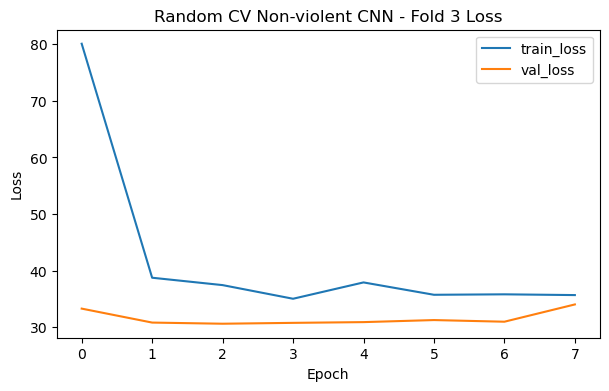


Random CV - Non-violent - Fold 4
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 61.6539 - mae: 4.7672 - val_loss: 32.3330 - val_mae: 3.8815
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 37.2602 - mae: 3.8710 - val_loss: 30.4640 - val_mae: 3.6846
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 36.5146 - mae: 3.8343 - val_loss: 34.0113 - val_mae: 3.7593
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 35.2028 - mae: 3.7590 - val_loss: 30.0821 - val_mae: 3.6922
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 35.1743 - mae: 3.7767 - val_loss: 31.7203 - val_mae: 3.7498
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 35.9947 - mae: 3.8025 - val_loss: 35.9764 - val_mae: 3.7912
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 34.4576 - mae: 3.7524 - val_loss: 29.8540 - val_mae: 3.7102
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 35.6020 - mae: 3.8022 - val_loss: 31.7636 - val_mae: 3.8304
Epo

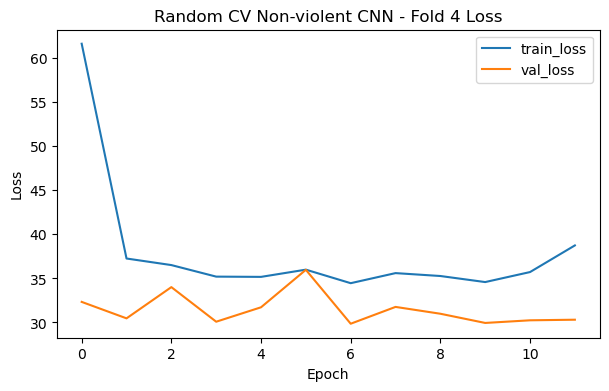


Random CV - Non-violent - Fold 5
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 68.8916 - mae: 4.7867 - val_loss: 36.8420 - val_mae: 3.9338
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 39.0773 - mae: 3.9444 - val_loss: 31.9179 - val_mae: 3.6588
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.9241 - mae: 3.8775 - val_loss: 30.6771 - val_mae: 3.6716
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.4524 - mae: 3.8661 - val_loss: 31.7766 - val_mae: 3.7052
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 35.1566 - mae: 3.8191 - val_loss: 31.3779 - val_mae: 3.6788
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.8485 - mae: 3.8437 - val_loss: 28.2139 - val_mae: 3.5497
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 40.3211 - mae: 3.8343 - val_loss: 28.6491 - val_mae: 3.5794
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 37.8058 - mae: 3.8463 - val_loss: 29.5843 - val_mae: 3.6315
Epo

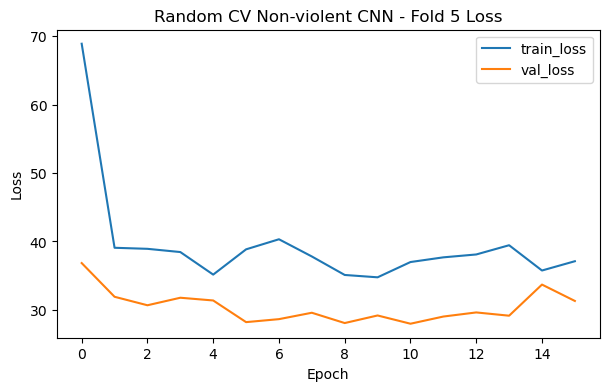


Random CV Non-violent Summary
   fold        mse       mae        r2
0     1  36.952419  3.648535  0.899574
1     2  31.236666  3.703495  0.886102
2     3  30.592964  3.579063  0.916858
3     4  29.853985  3.710235  0.901892
4     5  27.980682  3.553613  0.874311

Mean metrics
mse    31.323343
mae     3.638988
r2      0.895747
dtype: float64


In [57]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

random_results_nonviolent = []

for fold_id, (tr_idx, va_idx) in enumerate(kf.split(X_train_tab_cnn), start=1):
    print("\n" + "="*60)
    print(f"Random CV - Non-violent - Fold {fold_id}")
    print("="*60)

    X_tr_tab = X_train_tab_cnn[tr_idx]
    X_va_tab = X_train_tab_cnn[va_idx]

    X_tr_coord = coords_train_scaled[tr_idx]
    X_va_coord = coords_train_scaled[va_idx]

    y_tr = y_train_nonviolent[tr_idx]
    y_va = y_train_nonviolent[va_idx]

    tab_input = Input(shape=(X_train_tab_cnn.shape[1], 1))
    x = Conv1D(32, 3, activation="relu", padding="same")(tab_input)
    x = Dropout(0.2)(x)
    x = Conv1D(32, 3, activation="relu", padding="same")(x)
    x = Flatten()(x)

    coord_input = Input(shape=(2,))
    c = Dense(16, activation="relu")(coord_input)

    merged = Concatenate()([x, c])
    merged = Dense(64, activation="relu")(merged)
    merged = Dropout(0.2)(merged)
    output = Dense(1)(merged)

    model = Model(inputs=[tab_input, coord_input], outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss="mse", metrics=["mae"])

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    history = model.fit(
        [X_tr_tab, X_tr_coord], y_tr,
        validation_data=([X_va_tab, X_va_coord], y_va),
        epochs=50,
        batch_size=64,
        verbose=1,
        callbacks=[es]
    )

    pred_va = model.predict([X_va_tab, X_va_coord], verbose=0).ravel()

    mse = mean_squared_error(y_va, pred_va)
    mae = mean_absolute_error(y_va, pred_va)
    r2  = r2_score(y_va, pred_va)

    random_results_nonviolent.append({"fold": fold_id, "mse": mse, "mae": mae, "r2": r2})
    print(f"Fold {fold_id} -> MSE: {mse:.3f} | MAE: {mae:.3f} | R2: {r2:.3f}")

    plt.figure(figsize=(7,4))
    plt.plot(history.history["loss"], label="train_loss")
    plt.plot(history.history["val_loss"], label="val_loss")
    plt.title(f"Random CV Non-violent CNN - Fold {fold_id} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

random_results_nonviolent_df = pd.DataFrame(random_results_nonviolent)
print("\nRandom CV Non-violent Summary")
print(random_results_nonviolent_df)
print("\nMean metrics")
print(random_results_nonviolent_df[["mse", "mae", "r2"]].mean())

#### Spatial CV Violent CNN 


Spatial CV - Violent - Fold 1
Epoch 1/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 20.0436 - mae: 3.2747 - val_loss: 30.4202 - val_mae: 3.6458
Epoch 2/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 14.6839 - mae: 2.8466 - val_loss: 30.9156 - val_mae: 3.6185
Epoch 3/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 14.4503 - mae: 2.8288 - val_loss: 30.0353 - val_mae: 3.5918
Epoch 4/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 14.2200 - mae: 2.8226 - val_loss: 28.8289 - val_mae: 3.5572
Epoch 5/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 14.2366 - mae: 2.8235 - val_loss: 28.2441 - val_mae: 3.5594
Epoch 6/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 14.1644 - mae: 2.8149 - val_loss: 28.1445 - val_mae: 3.5435
Epoch 7/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 14.1795 - mae: 2.8143 - val_loss: 29.1226 - val_mae: 3.5610
Epoch 8/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 14.1553 - mae: 2.8152 - val_loss: 29.9665 - val_mae: 3.5677
Epoch

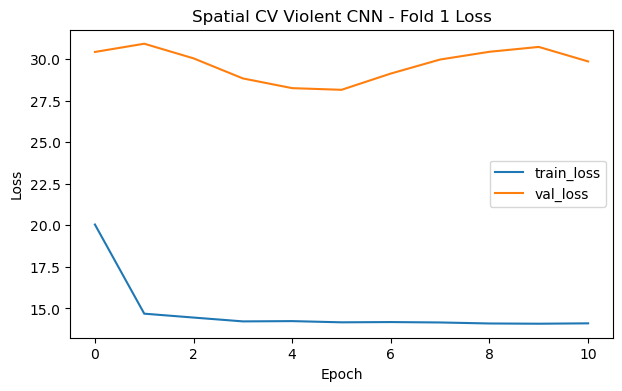


Spatial CV - Violent - Fold 2
Epoch 1/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 31.6807 - mae: 3.5933 - val_loss: 18.4483 - val_mae: 3.2385
Epoch 2/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 19.8685 - mae: 3.0125 - val_loss: 17.7945 - val_mae: 3.1925
Epoch 3/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.8731 - mae: 2.9916 - val_loss: 17.8957 - val_mae: 3.2071
Epoch 4/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.8513 - mae: 2.9750 - val_loss: 17.6265 - val_mae: 3.1802
Epoch 5/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.2285 - mae: 2.9923 - val_loss: 17.3748 - val_mae: 3.1617
Epoch 6/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.9145 - mae: 2.9713 - val_loss: 16.9617 - val_mae: 3.1217
Epoch 7/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.7849 - mae: 2.9897 - val_loss: 17.5023 - val_mae: 3.1638
Epoch 8/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.6121 - mae: 3.0120 - val_loss: 17.3134 - val_mae: 3.1603
Epoch 9

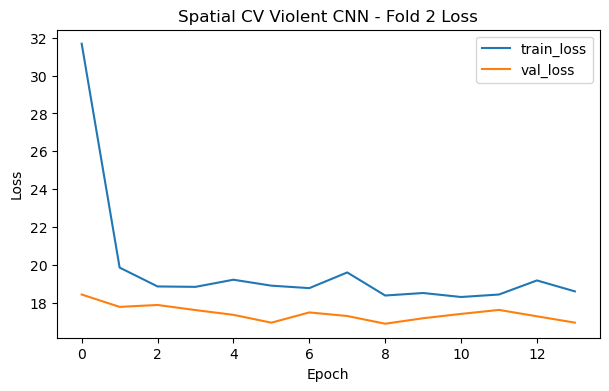


Spatial CV - Violent - Fold 3
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 33.1096 - mae: 3.7277 - val_loss: 12.7852 - val_mae: 2.7827
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 20.3803 - mae: 3.1370 - val_loss: 12.7289 - val_mae: 2.7679
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.9228 - mae: 3.1113 - val_loss: 12.7653 - val_mae: 2.7066
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 20.8088 - mae: 3.1300 - val_loss: 12.6763 - val_mae: 2.7095
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.7990 - mae: 3.0769 - val_loss: 12.6402 - val_mae: 2.7056
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.3180 - mae: 3.0864 - val_loss: 12.5586 - val_mae: 2.7408
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 20.0038 - mae: 3.0966 - val_loss: 12.5627 - val_mae: 2.7436
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.9570 - mae: 3.0802 - val_loss: 12.6365 - val_mae: 2.7078
Epoch 9/

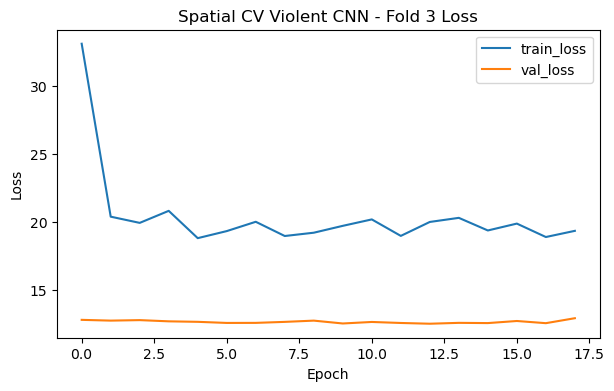


Spatial CV - Violent - Fold 4
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 27.9613 - mae: 3.6277 - val_loss: 14.4342 - val_mae: 2.7966
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 20.0740 - mae: 3.1396 - val_loss: 14.1935 - val_mae: 2.7957
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.9739 - mae: 3.0779 - val_loss: 14.0591 - val_mae: 2.7365
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.1108 - mae: 3.0900 - val_loss: 14.1211 - val_mae: 2.7263
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.8195 - mae: 3.0688 - val_loss: 13.8293 - val_mae: 2.7459
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.8904 - mae: 3.0906 - val_loss: 13.8433 - val_mae: 2.7342
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.1387 - mae: 3.0791 - val_loss: 13.7281 - val_mae: 2.7092
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 20.2889 - mae: 3.1148 - val_loss: 13.9499 - val_mae: 2.7233
Epoch 9/

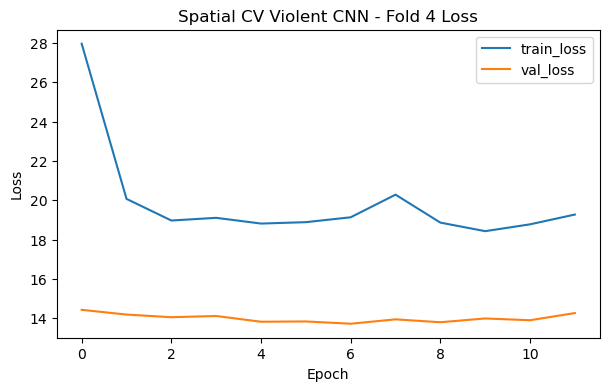


Spatial CV - Violent - Fold 5
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 30.4993 - mae: 3.7783 - val_loss: 12.6873 - val_mae: 2.6091
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 20.0445 - mae: 3.1818 - val_loss: 12.2383 - val_mae: 2.6159
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.4223 - mae: 3.1499 - val_loss: 12.0687 - val_mae: 2.5824
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.7748 - mae: 3.1427 - val_loss: 11.9618 - val_mae: 2.5487
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.4201 - mae: 3.1279 - val_loss: 12.0326 - val_mae: 2.5398
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 20.1793 - mae: 3.1504 - val_loss: 12.2233 - val_mae: 2.6426
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 18.6936 - mae: 3.1111 - val_loss: 12.0955 - val_mae: 2.6037
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 19.6530 - mae: 3.1210 - val_loss: 12.3152 - val_mae: 2.5774
Epoch 9/

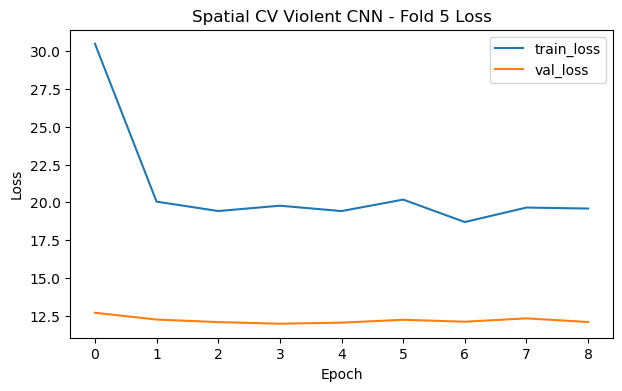


Spatial CV Violent Summary
   fold        mse       mae        r2
0     1  28.144451  3.543482  0.877422
1     2  16.906487  3.130067  0.348430
2     3  12.500557  2.716683  0.377427
3     4  13.728069  2.709201  0.550139
4     5  11.961845  2.548743  0.613961

Mean metrics
mse    16.648282
mae     2.929635
r2      0.553476
dtype: float64


In [58]:
groups = gdf_train_proj["cluster"].values
gkf = GroupKFold(n_splits=5)

spatial_results_violent = []

for fold_id, (tr_idx, va_idx) in enumerate(gkf.split(X_train_tab_cnn, y_train_violent, groups=groups), start=1):
    print("\n" + "="*60)
    print(f"Spatial CV - Violent - Fold {fold_id}")
    print("="*60)

    X_tr_tab = X_train_tab_cnn[tr_idx]
    X_va_tab = X_train_tab_cnn[va_idx]

    X_tr_coord = coords_train_scaled[tr_idx]
    X_va_coord = coords_train_scaled[va_idx]

    y_tr = y_train_violent[tr_idx]
    y_va = y_train_violent[va_idx]

    tab_input = Input(shape=(X_train_tab_cnn.shape[1], 1))
    x = Conv1D(32, 3, activation="relu", padding="same")(tab_input)
    x = Dropout(0.2)(x)
    x = Conv1D(32, 3, activation="relu", padding="same")(x)
    x = Flatten()(x)

    coord_input = Input(shape=(2,))
    c = Dense(16, activation="relu")(coord_input)

    merged = Concatenate()([x, c])
    merged = Dense(64, activation="relu")(merged)
    merged = Dropout(0.2)(merged)
    output = Dense(1)(merged)

    model = Model(inputs=[tab_input, coord_input], outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss="mse", metrics=["mae"])

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    history = model.fit(
        [X_tr_tab, X_tr_coord], y_tr,
        validation_data=([X_va_tab, X_va_coord], y_va),
        epochs=50,
        batch_size=64,
        verbose=1,
        callbacks=[es]
    )

    pred_va = model.predict([X_va_tab, X_va_coord], verbose=0).ravel()

    mse = mean_squared_error(y_va, pred_va)
    mae = mean_absolute_error(y_va, pred_va)
    r2  = r2_score(y_va, pred_va)

    spatial_results_violent.append({"fold": fold_id, "mse": mse, "mae": mae, "r2": r2})
    print(f"Fold {fold_id} -> MSE: {mse:.3f} | MAE: {mae:.3f} | R2: {r2:.3f}")

    plt.figure(figsize=(7,4))
    plt.plot(history.history["loss"], label="train_loss")
    plt.plot(history.history["val_loss"], label="val_loss")
    plt.title(f"Spatial CV Violent CNN - Fold {fold_id} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

spatial_results_violent_df = pd.DataFrame(spatial_results_violent)
print("\nSpatial CV Violent Summary")
print(spatial_results_violent_df)
print("\nMean metrics")
print(spatial_results_violent_df[["mse", "mae", "r2"]].mean())

#### Spatial CV Non violent


Spatial CV - Non-violent - Fold 1
Epoch 1/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 40.1177 - mae: 4.2564 - val_loss: 65.1117 - val_mae: 4.7916
Epoch 2/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 25.3416 - mae: 3.4899 - val_loss: 89.3901 - val_mae: 5.1332
Epoch 3/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 24.7566 - mae: 3.4459 - val_loss: 72.8816 - val_mae: 4.8583
Epoch 4/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 24.5766 - mae: 3.4437 - val_loss: 78.4464 - val_mae: 4.9404
Epoch 5/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 24.9138 - mae: 3.4602 - val_loss: 90.6582 - val_mae: 5.1195
Epoch 6/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 24.4303 - mae: 3.4314 - val_loss: 79.9872 - val_mae: 4.9717
Fold 1 -> MSE: 65.112 | MAE: 4.792 | R2: 0.942


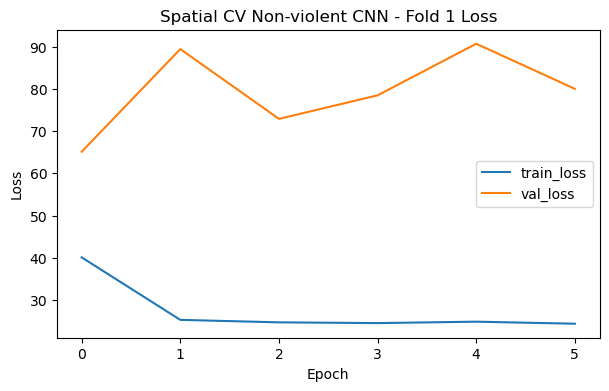


Spatial CV - Non-violent - Fold 2
Epoch 1/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 96.0994 - mae: 5.0526 - val_loss: 39.2447 - val_mae: 4.0483
Epoch 2/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 43.7788 - mae: 4.0518 - val_loss: 33.7823 - val_mae: 3.8433
Epoch 3/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 40.0927 - mae: 3.8962 - val_loss: 32.9157 - val_mae: 3.7294
Epoch 4/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.5351 - mae: 3.8661 - val_loss: 30.7671 - val_mae: 3.6519
Epoch 5/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.1731 - mae: 3.8443 - val_loss: 30.3662 - val_mae: 3.6468
Epoch 6/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 39.2458 - mae: 3.8492 - val_loss: 29.1465 - val_mae: 3.6350
Epoch 7/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 35.4910 - mae: 3.7579 - val_loss: 30.2996 - val_mae: 3.6359
Epoch 8/50
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 42.9294 - mae: 3.9952 - val_loss: 29.2763 - val_mae: 3.6345
Epoc

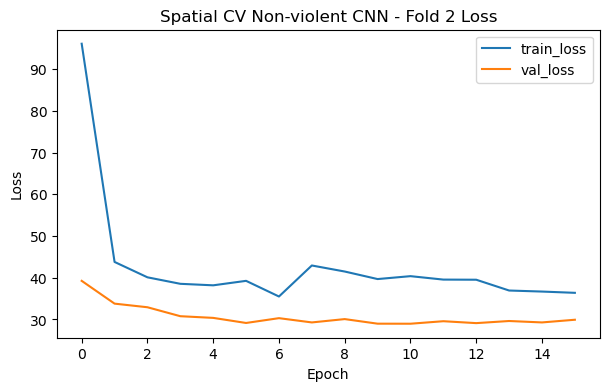


Spatial CV - Non-violent - Fold 3
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 93.8645 - mae: 5.1205 - val_loss: 23.0786 - val_mae: 3.3552
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 42.6107 - mae: 4.0820 - val_loss: 21.1509 - val_mae: 3.2430
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 41.1275 - mae: 3.9839 - val_loss: 22.5509 - val_mae: 3.3059
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 42.1876 - mae: 4.0003 - val_loss: 21.1536 - val_mae: 3.3954
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.4889 - mae: 3.9593 - val_loss: 20.4715 - val_mae: 3.2011
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 37.4108 - mae: 3.8910 - val_loss: 20.4636 - val_mae: 3.2141
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 39.6327 - mae: 3.9205 - val_loss: 20.4367 - val_mae: 3.2297
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.5852 - mae: 3.9233 - val_loss: 20.9231 - val_mae: 3.2054
Epo

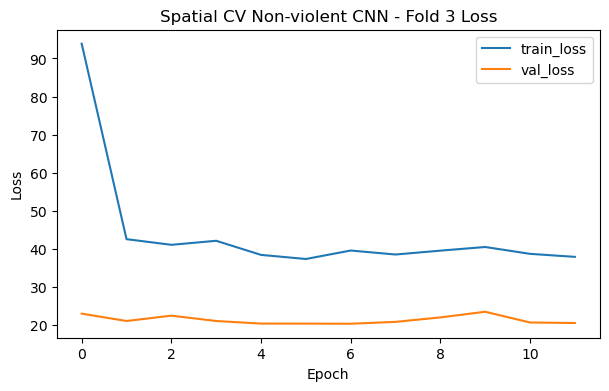


Spatial CV - Non-violent - Fold 4
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 74.6623 - mae: 4.9638 - val_loss: 29.6386 - val_mae: 3.6679
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 45.9822 - mae: 4.0703 - val_loss: 26.5681 - val_mae: 3.5185
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 41.0501 - mae: 3.9886 - val_loss: 26.0013 - val_mae: 3.4530
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 36.6624 - mae: 3.8499 - val_loss: 24.8894 - val_mae: 3.4324
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 37.9524 - mae: 3.8574 - val_loss: 25.3478 - val_mae: 3.4621
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 40.3766 - mae: 3.9093 - val_loss: 25.4824 - val_mae: 3.4449
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.3860 - mae: 3.8796 - val_loss: 24.6534 - val_mae: 3.4269
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38.3511 - mae: 3.8777 - val_loss: 24.8213 - val_mae: 3.4297
Epoc

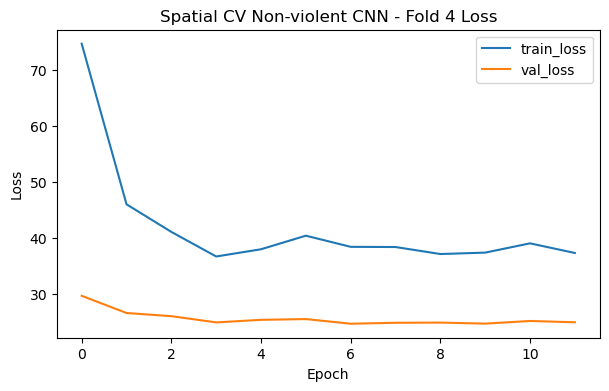


Spatial CV - Non-violent - Fold 5
Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 71.2366 - mae: 4.9920 - val_loss: 28.9989 - val_mae: 3.4631
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 43.2182 - mae: 4.1163 - val_loss: 25.7036 - val_mae: 3.3216
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 40.7063 - mae: 3.9672 - val_loss: 22.2795 - val_mae: 3.1923
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 41.0971 - mae: 3.9983 - val_loss: 23.2076 - val_mae: 3.2291
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 39.2709 - mae: 3.9578 - val_loss: 21.5401 - val_mae: 3.1607
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 39.2163 - mae: 3.9421 - val_loss: 21.0575 - val_mae: 3.1647
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 41.7095 - mae: 3.9907 - val_loss: 22.8930 - val_mae: 3.2111
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 36.3314 - mae: 3.9010 - val_loss: 21.9298 - val_mae: 3.1700
Epoc

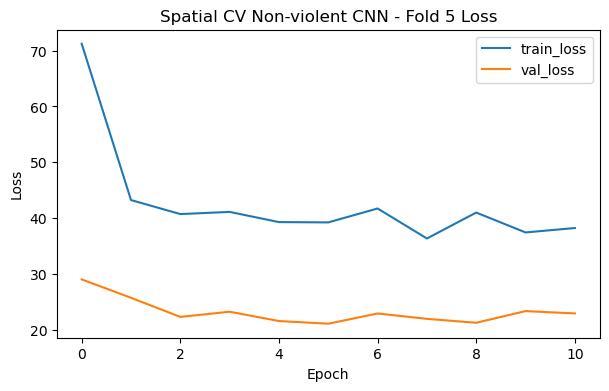


Spatial CV Non-violent Summary
   fold        mse       mae        r2
0     1  65.111687  4.791595  0.941924
1     2  28.966263  3.633747  0.725114
2     3  20.436731  3.229748  0.558943
3     4  24.653419  3.426856  0.754712
4     5  21.057465  3.164659  0.719890

Mean metrics
mse    32.045113
mae     3.649321
r2      0.740117
dtype: float64


In [59]:
groups = gdf_train_proj["cluster"].values
gkf = GroupKFold(n_splits=5)

spatial_results_nonviolent = []

for fold_id, (tr_idx, va_idx) in enumerate(gkf.split(X_train_tab_cnn, y_train_nonviolent, groups=groups), start=1):
    print("\n" + "="*60)
    print(f"Spatial CV - Non-violent - Fold {fold_id}")
    print("="*60)

    X_tr_tab = X_train_tab_cnn[tr_idx]
    X_va_tab = X_train_tab_cnn[va_idx]

    X_tr_coord = coords_train_scaled[tr_idx]
    X_va_coord = coords_train_scaled[va_idx]

    y_tr = y_train_nonviolent[tr_idx]
    y_va = y_train_nonviolent[va_idx]

    tab_input = Input(shape=(X_train_tab_cnn.shape[1], 1))
    x = Conv1D(32, 3, activation="relu", padding="same")(tab_input)
    x = Dropout(0.2)(x)
    x = Conv1D(32, 3, activation="relu", padding="same")(x)
    x = Flatten()(x)

    coord_input = Input(shape=(2,))
    c = Dense(16, activation="relu")(coord_input)

    merged = Concatenate()([x, c])
    merged = Dense(64, activation="relu")(merged)
    merged = Dropout(0.2)(merged)
    output = Dense(1)(merged)

    model = Model(inputs=[tab_input, coord_input], outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss="mse", metrics=["mae"])

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    history = model.fit(
        [X_tr_tab, X_tr_coord], y_tr,
        validation_data=([X_va_tab, X_va_coord], y_va),
        epochs=50,
        batch_size=64,
        verbose=1,
        callbacks=[es]
    )

    pred_va = model.predict([X_va_tab, X_va_coord], verbose=0).ravel()

    mse = mean_squared_error(y_va, pred_va)
    mae = mean_absolute_error(y_va, pred_va)
    r2  = r2_score(y_va, pred_va)

    spatial_results_nonviolent.append({"fold": fold_id, "mse": mse, "mae": mae, "r2": r2})
    print(f"Fold {fold_id} -> MSE: {mse:.3f} | MAE: {mae:.3f} | R2: {r2:.3f}")

    plt.figure(figsize=(7,4))
    plt.plot(history.history["loss"], label="train_loss")
    plt.plot(history.history["val_loss"], label="val_loss")
    plt.title(f"Spatial CV Non-violent CNN - Fold {fold_id} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

spatial_results_nonviolent_df = pd.DataFrame(spatial_results_nonviolent)
print("\nSpatial CV Non-violent Summary")
print(spatial_results_nonviolent_df)
print("\nMean metrics")
print(spatial_results_nonviolent_df[["mse", "mae", "r2"]].mean())

#### Final Held Out Test Violent

Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 22.0194 - mae: 3.4301 - val_loss: 28.2394 - val_mae: 3.3116
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 15.3065 - mae: 2.9329 - val_loss: 31.5467 - val_mae: 3.3562
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 15.0560 - mae: 2.8999 - val_loss: 29.7172 - val_mae: 3.3116
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 15.0197 - mae: 2.9039 - val_loss: 29.9092 - val_mae: 3.3260
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 15.0215 - mae: 2.8999 - val_loss: 28.2314 - val_mae: 3.2817
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 14.9975 - mae: 2.8981 - val_loss: 27.6486 - val_mae: 3.2707
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 15.0186 - mae: 2.8985 - val_loss: 26.7663 - val_mae: 3.2560
Epoch 8/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 14.9699 - mae: 2.8995 - val_loss: 28.9994 - val_mae: 3.3004
Epoch 9/50
206/206 ━━━━━━━━━━━━━━━━━━━

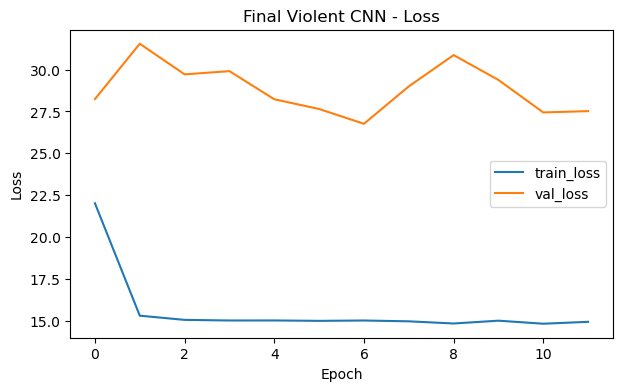

In [60]:
final_model_violent = Model(
    inputs=base_model.inputs,
    outputs=base_model.outputs
)

final_model_violent.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="mse",
    metrics=["mae"]
)

es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history_final_violent = final_model_violent.fit(
    [X_train_tab_cnn, coords_train_scaled], y_train_violent,
    validation_split=0.2,
    epochs=50,
    batch_size=64,
    verbose=1,
    callbacks=[es]
)

pred_test_violent = final_model_violent.predict([X_test_tab_cnn, coords_test_scaled], verbose=0).ravel()

print("\nFinal Violent CNN (Held-out Time Test)")
print("MSE:", mean_squared_error(y_test_violent, pred_test_violent))
print("MAE:", mean_absolute_error(y_test_violent, pred_test_violent))
print("R2 :", r2_score(y_test_violent, pred_test_violent))

plt.figure(figsize=(7,4))
plt.plot(history_final_violent.history["loss"], label="train_loss")
plt.plot(history_final_violent.history["val_loss"], label="val_loss")
plt.title("Final Violent CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

#### Final Held out Test Non violent

Epoch 1/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 47.3482 - mae: 4.4599 - val_loss: 60.5196 - val_mae: 4.3269
Epoch 2/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 29.4404 - mae: 3.6600 - val_loss: 52.7722 - val_mae: 4.2077
Epoch 3/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 28.8361 - mae: 3.6334 - val_loss: 61.2527 - val_mae: 4.2958
Epoch 4/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 28.8217 - mae: 3.6195 - val_loss: 53.4113 - val_mae: 4.1938
Epoch 5/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 29.1960 - mae: 3.6459 - val_loss: 60.4045 - val_mae: 4.2698
Epoch 6/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 28.6901 - mae: 3.6102 - val_loss: 57.7823 - val_mae: 4.2429
Epoch 7/50
206/206 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 28.1661 - mae: 3.5838 - val_loss: 61.6558 - val_mae: 4.2703

Final Non-violent CNN (Held-out Time Test)
MSE: 27.978168487548828
MAE: 3.443512439727783
R2 : 0.9140478372573853


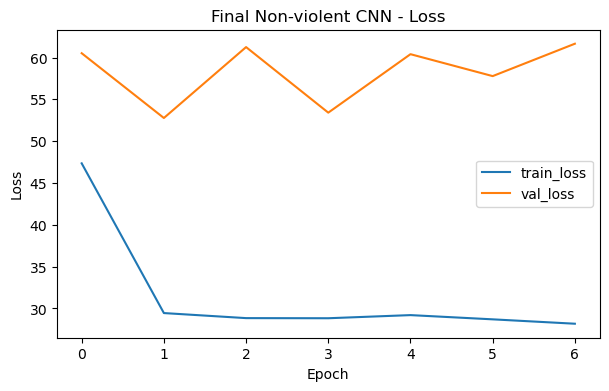

In [61]:
# I rebuild the final model cleanly for non-violent prediction.
tab_input = Input(shape=(X_train_tab_cnn.shape[1], 1))
x = Conv1D(32, 3, activation="relu", padding="same")(tab_input)
x = Dropout(0.2)(x)
x = Conv1D(32, 3, activation="relu", padding="same")(x)
x = Flatten()(x)

coord_input = Input(shape=(2,))
c = Dense(16, activation="relu")(coord_input)

merged = Concatenate()([x, c])
merged = Dense(64, activation="relu")(merged)
merged = Dropout(0.2)(merged)
output = Dense(1)(merged)

final_model_nonviolent = Model(inputs=[tab_input, coord_input], outputs=output)

final_model_nonviolent.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="mse",
    metrics=["mae"]
)

es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history_final_nonviolent = final_model_nonviolent.fit(
    [X_train_tab_cnn, coords_train_scaled], y_train_nonviolent,
    validation_split=0.2,
    epochs=50,
    batch_size=64,
    verbose=1,
    callbacks=[es]
)

pred_test_nonviolent = final_model_nonviolent.predict([X_test_tab_cnn, coords_test_scaled], verbose=0).ravel()

print("\nFinal Non-violent CNN (Held-out Time Test)")
print("MSE:", mean_squared_error(y_test_nonviolent, pred_test_nonviolent))
print("MAE:", mean_absolute_error(y_test_nonviolent, pred_test_nonviolent))
print("R2 :", r2_score(y_test_nonviolent, pred_test_nonviolent))

plt.figure(figsize=(7,4))
plt.plot(history_final_nonviolent.history["loss"], label="train_loss")
plt.plot(history_final_nonviolent.history["val_loss"], label="val_loss")
plt.title("Final Non-violent CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.savefig("Final Non-Violent CNN.png")
plt.show()

### Putting muy Results in  a Dataframe

In [62]:
pred_test_nonviolent = final_model_nonviolent.predict(
    [X_test_tab_cnn, coords_test_scaled],
    verbose=0
).ravel()

In [130]:


results = []

# RANDOM FOREST (FINAL TEST)
results.append({
    "Model": "Random Forest",
    "Target": "Violent",
    "Evaluation": "Final Test",
    "MSE": mean_squared_error(y_test_v, pred_v),
    "MAE": mean_absolute_error(y_test_v, pred_v),
    "R2": r2_score(y_test_v, pred_v)
})

results.append({
    "Model": "Random Forest",
    "Target": "Non-violent",
    "Evaluation": "Final Test",
    "MSE": mean_squared_error(y_test_nv, pred_nv),
    "MAE": mean_absolute_error(y_test_nv, pred_nv),
    "R2": r2_score(y_test_nv, pred_nv)
})


# SVR (FINAL TEST)
results.append({
    "Model": "SVR",
    "Target": "Violent",
    "Evaluation": "Final Test",
    "MSE": mean_squared_error(y_te, pred_te),
    "MAE": mean_absolute_error(y_te, pred_te),
    "R2": r2_score(y_te, pred_te)
})

results.append({
    "Model": "SVR",
    "Target": "Non-Violent",
    "Evaluation": "Final Test",
    "MSE": mean_squared_error(y_te, pred_nv),
    "MAE": mean_absolute_error(y_te, pred_nv),
    "R2": r2_score(y_te, pred_nv)
})


# CNN (FINAL TEST)
results.append({
    "Model": "CNN",
    "Target": "Violent",
    "Evaluation": "Final Test",
    "MSE": mean_squared_error(y_test_violent, pred_test_violent),
    "MAE": mean_absolute_error(y_test_violent, pred_test_violent),
    "R2": r2_score(y_test_violent, pred_test_violent)
})

results.append({
    "Model": "CNN",
    "Target": "Non-violent",
    "Evaluation": "Final Test",
    "MSE": mean_squared_error(y_test_nonviolent, pred_test_nonviolent),
    "MAE": mean_absolute_error(y_test_nonviolent, pred_test_nonviolent),
    "R2": r2_score(y_test_nonviolent, pred_test_nonviolent)
})


# CNN RANDOM CV (MEAN)
results.append({
    "Model": "CNN",
    "Target": "Violent",
    "Evaluation": "Random CV (Mean)",
    "MSE": random_results_violent_df["mse"].mean(),
    "MAE": random_results_violent_df["mae"].mean(),
    "R2": random_results_violent_df["r2"].mean()
})

results.append({
    "Model": "CNN",
    "Target": "Non-violent",
    "Evaluation": "Random CV (Mean)",
    "MSE": random_results_nonviolent_df["mse"].mean(),
    "MAE": random_results_nonviolent_df["mae"].mean(),
    "R2": random_results_nonviolent_df["r2"].mean()
})

# CNN SPATIAL CV (MEAN)
results.append({
    "Model": "CNN",
    "Target": "Violent",
    "Evaluation": "Spatial CV (Mean)",
    "MSE": spatial_results_violent_df["mse"].mean(),
    "MAE": spatial_results_violent_df["mae"].mean(),
    "R2": spatial_results_violent_df["r2"].mean()
})

results.append({
    "Model": "CNN",
    "Target": "Non-violent",
    "Evaluation": "Spatial CV (Mean)",
    "MSE": spatial_results_nonviolent_df["mse"].mean(),
    "MAE": spatial_results_nonviolent_df["mae"].mean(),
    "R2": spatial_results_nonviolent_df["r2"].mean()
})

# LSTM (FINAL TEST)

results.append({
    "Model": "LSTM",
    "Target": "Violent",
    "Evaluation": "Final Test",
    "MSE": mean_squared_error(y_v_test, pred_test_lstm_violent),
    "MAE": mean_absolute_error(y_v_test, pred_test_lstm_violent),
    "R2": r2_score(y_v_test, pred_test_lstm_violent)
})

results.append({
    "Model": "LSTM",
    "Target": "Non-violent",
    "Evaluation": "Final Test",
    "MSE": mean_squared_error(y_nv_test, pred_test_lstm_nonviolent),
    "MAE": mean_absolute_error(y_nv_test, pred_test_lstm_nonviolent),
    "R2": r2_score(y_nv_test, pred_test_lstm_nonviolent)
})

# CREATE RESULTS DATAFRAME
results_df = pd.DataFrame(results)

results_df["MSE"] = results_df["MSE"].round(3)
results_df["MAE"] = results_df["MAE"].round(3)
results_df["R2"] = results_df["R2"].round(3)

results_df = results_df.sort_values(by=["Target", "Evaluation", "R2"], ascending=[True, True, False]).reset_index(drop=True)

results_df

,Model,Target,Evaluation,MSE,MAE,R2
0,SVR,Non-Violent,Final Test,16.494,2.879,0.789
1,CNN,Non-violent,Final Test,27.978,3.444,0.914
2,LSTM,Non-violent,Final Test,33.330,3.681,0.884
3,Random Forest,Non-violent,Final Test,153.946,5.194,0.527
4,CNN,Non-violent,Random CV (Mean),31.323,3.639,0.896
5,CNN,Non-violent,Spatial CV (Mean),32.045,3.649,0.740
6,Random Forest,Violent,Final Test,16.494,2.879,0.789
7,SVR,Violent,Final Test,16.494,2.879,0.789
8,CNN,Violent,Final Test,16.680,2.865,0.787
9,LSTM,Violent,Final Test,16.135,3.016,0.743
